<a href="https://colab.research.google.com/github/CiaraFarrellSETU/phd/blob/main/TurloughNDVI_boxplot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

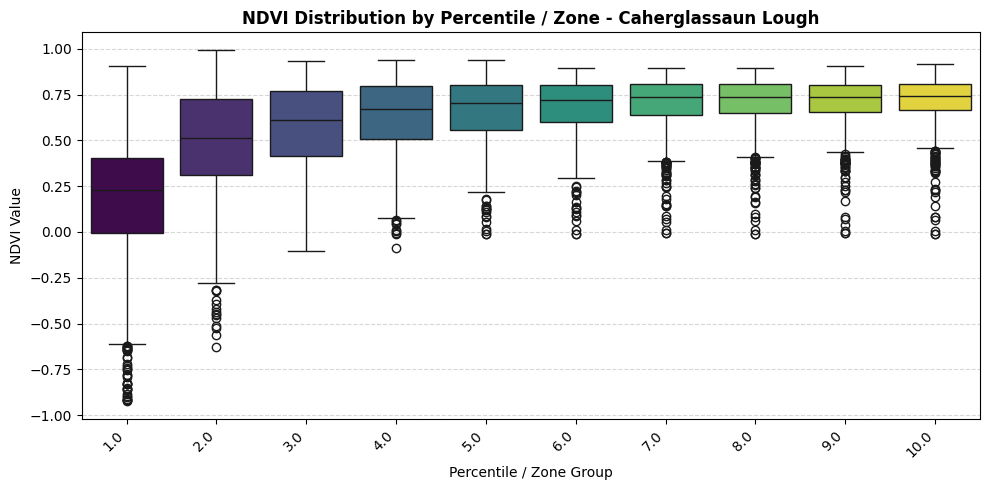

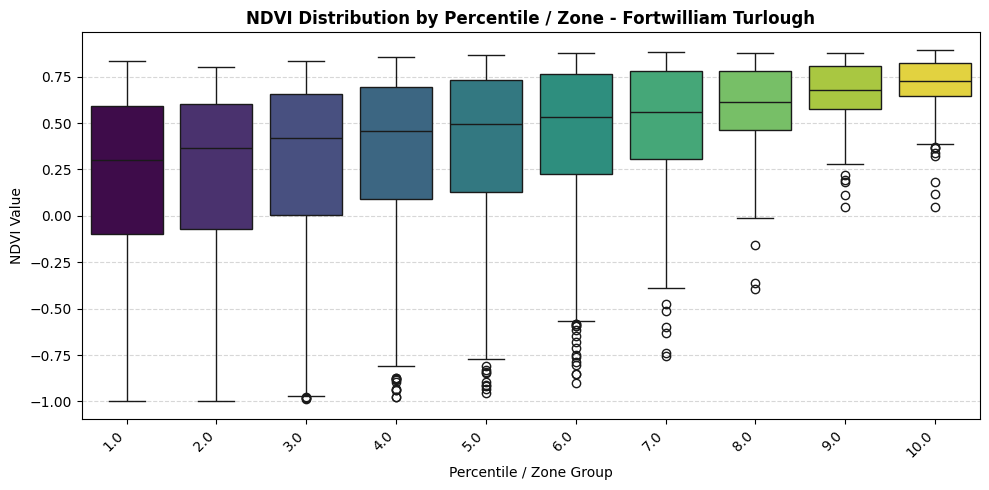

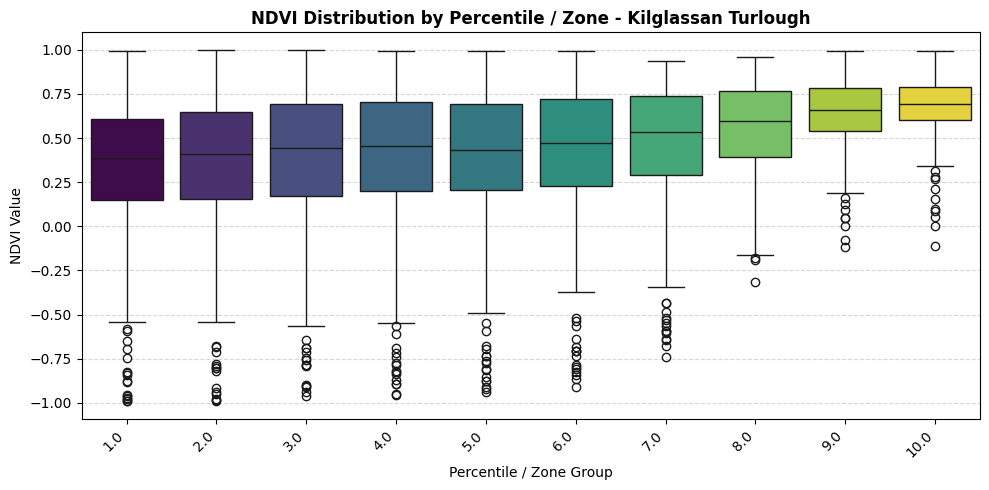

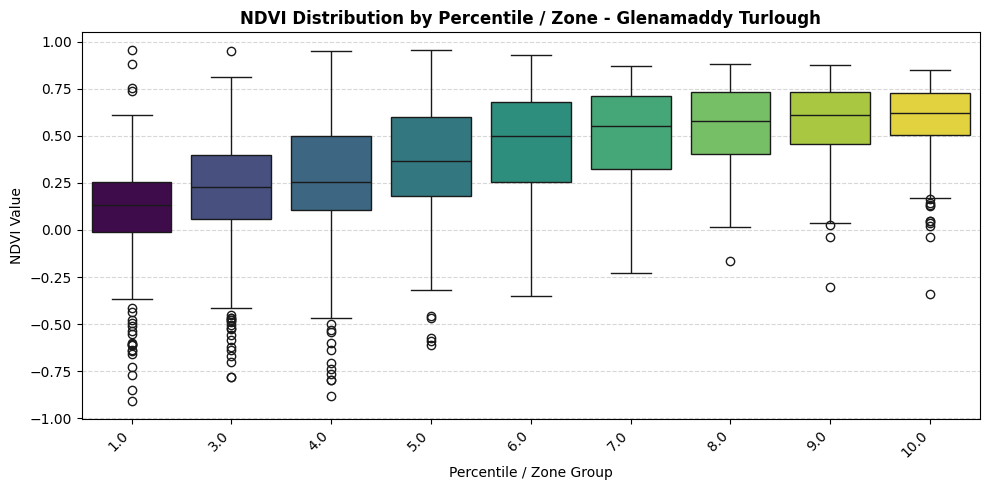

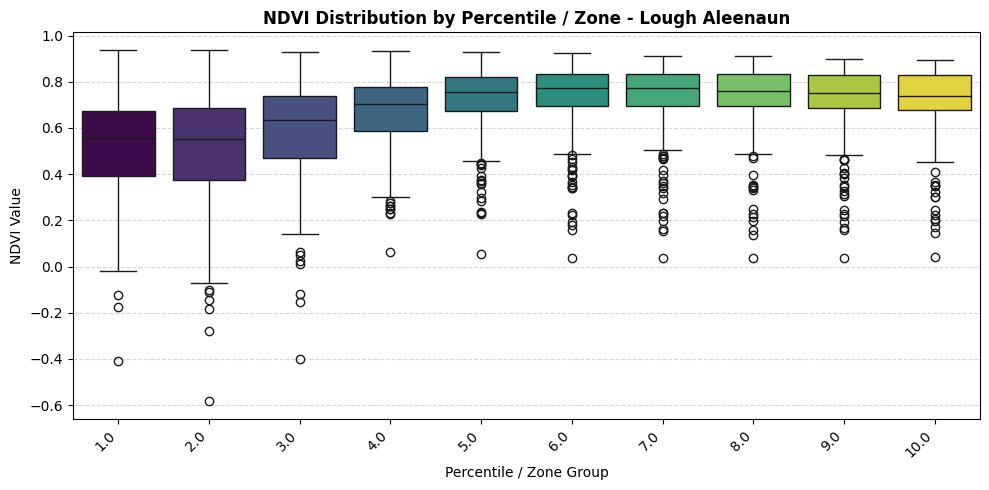

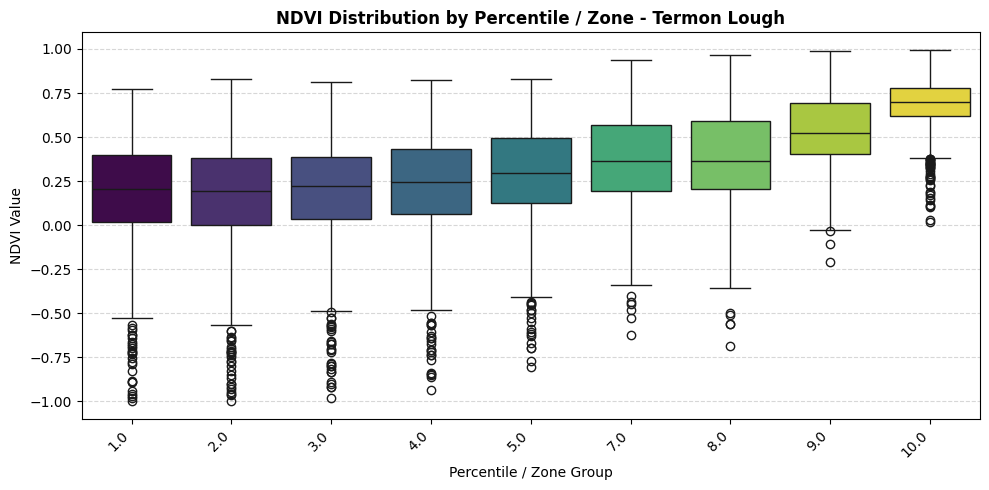

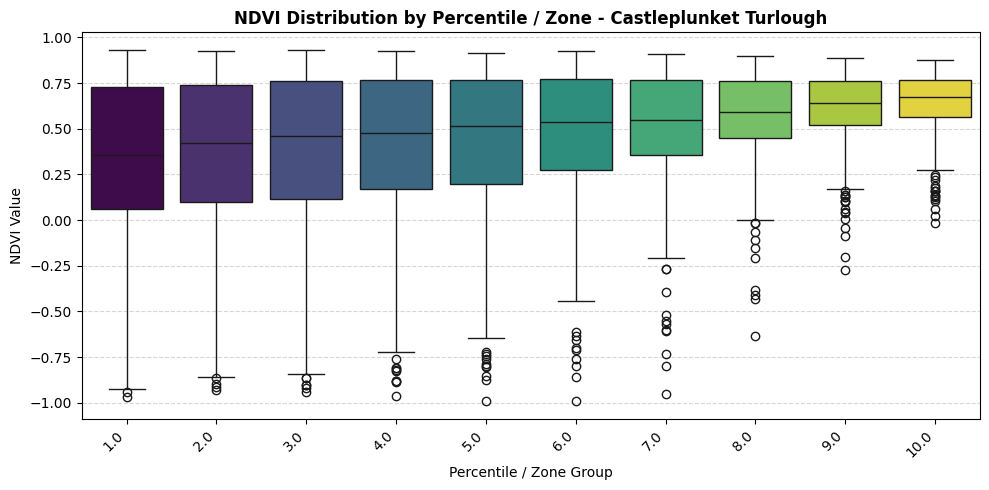

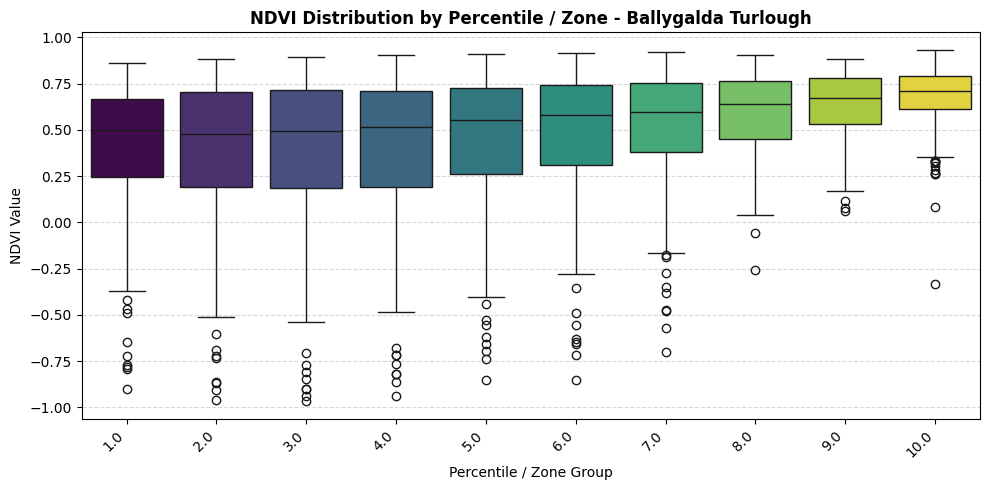

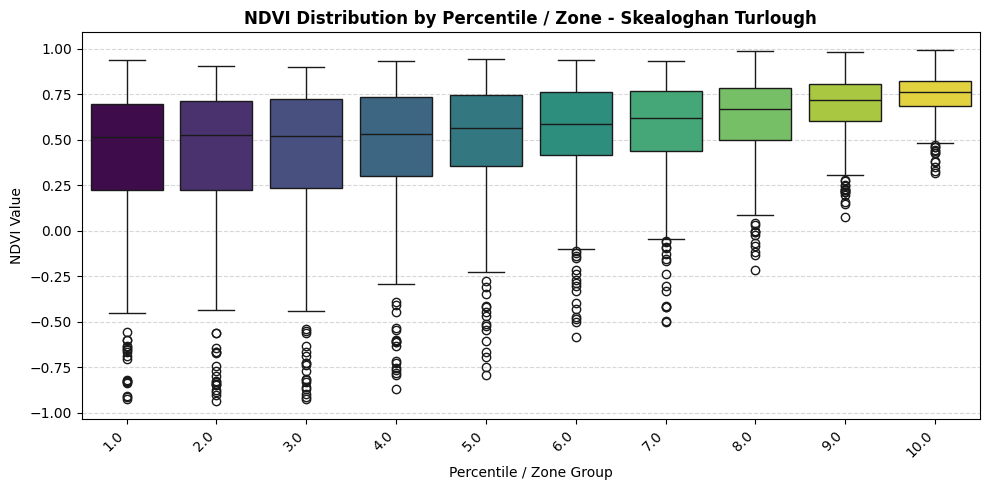

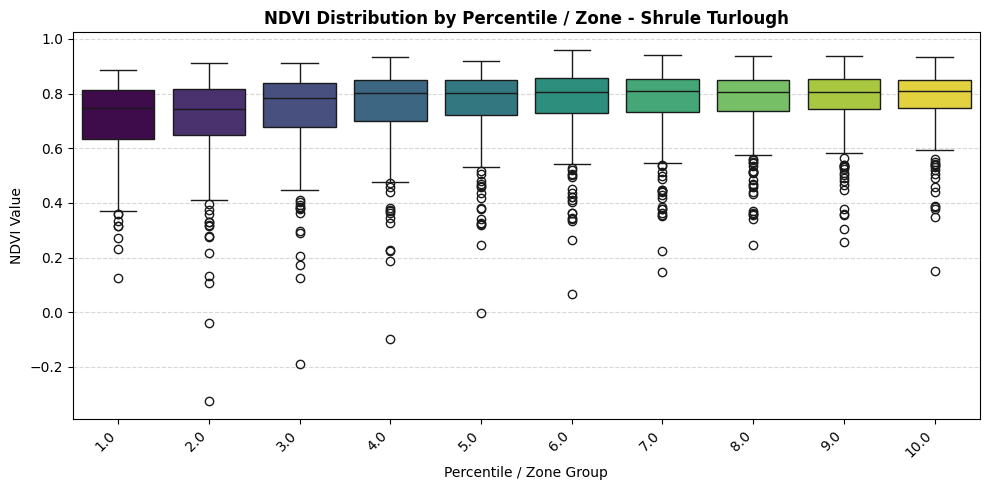

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# List of files to process
files = [
    '/content/Caherglassaun_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Fortwilliam_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Kilglassan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Glenamaddy_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Lough_Aleenaun_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Termon_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Castleplunket_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Ballygalda_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Skealoghan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Shrule_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv'
]

for file_path in files:
    if os.path.exists(file_path):
        # Get site name from the filename
        site_name = os.path.basename(file_path).split('_Zonal_')[0].replace('_', ' ')

        # Load CSV
        df = pd.read_csv(file_path)

        # Find columns
        ndvi_col = [col for col in df.columns if 'ndvi' in col.lower()]
        tile_col = [col for col in df.columns if 'tile' in col.lower() or 'zone_name' in col.lower()]

        if not tile_col and 'zone_id' in df.columns:
            tile_col = ['zone_id']

        if ndvi_col and tile_col:
            col_name = ndvi_col[0]
            t_col = tile_col[0]

            # Clean and filter data for plotting
            plot_df = df[[t_col, col_name]].dropna()

            # Create separate boxplot for each site showing percentiles/tiles
            plt.figure(figsize=(10, 5))
            sns.boxplot(data=plot_df, x=t_col, y=col_name, hue=t_col, palette='viridis', legend=False)
            plt.title(f'NDVI Distribution by Percentile / Zone - {site_name}', fontsize=12, fontweight='bold')
            plt.xlabel('Percentile / Zone Group', fontsize=10)
            plt.ylabel('NDVI Value', fontsize=10)
            plt.xticks(rotation=45, ha='right')
            plt.grid(axis='y', linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()
        else:
            print(f"Warning: Could not resolve NDVI or Tile columns in {site_name}")

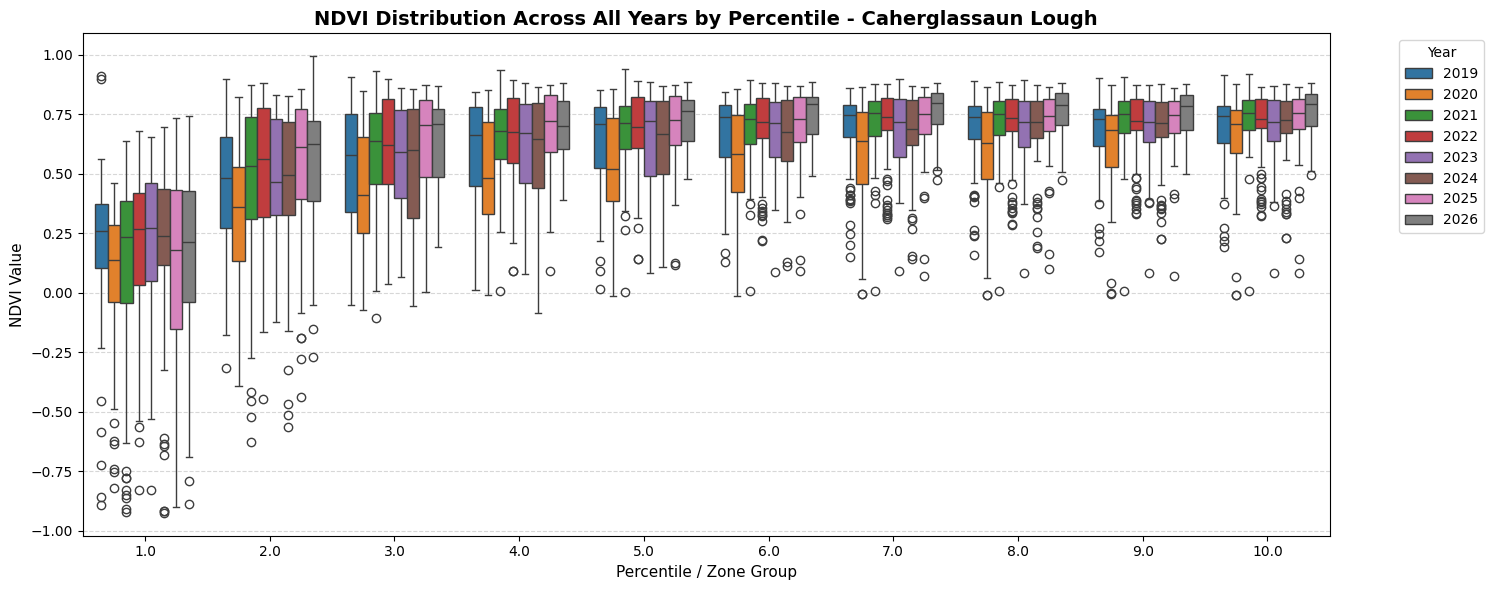

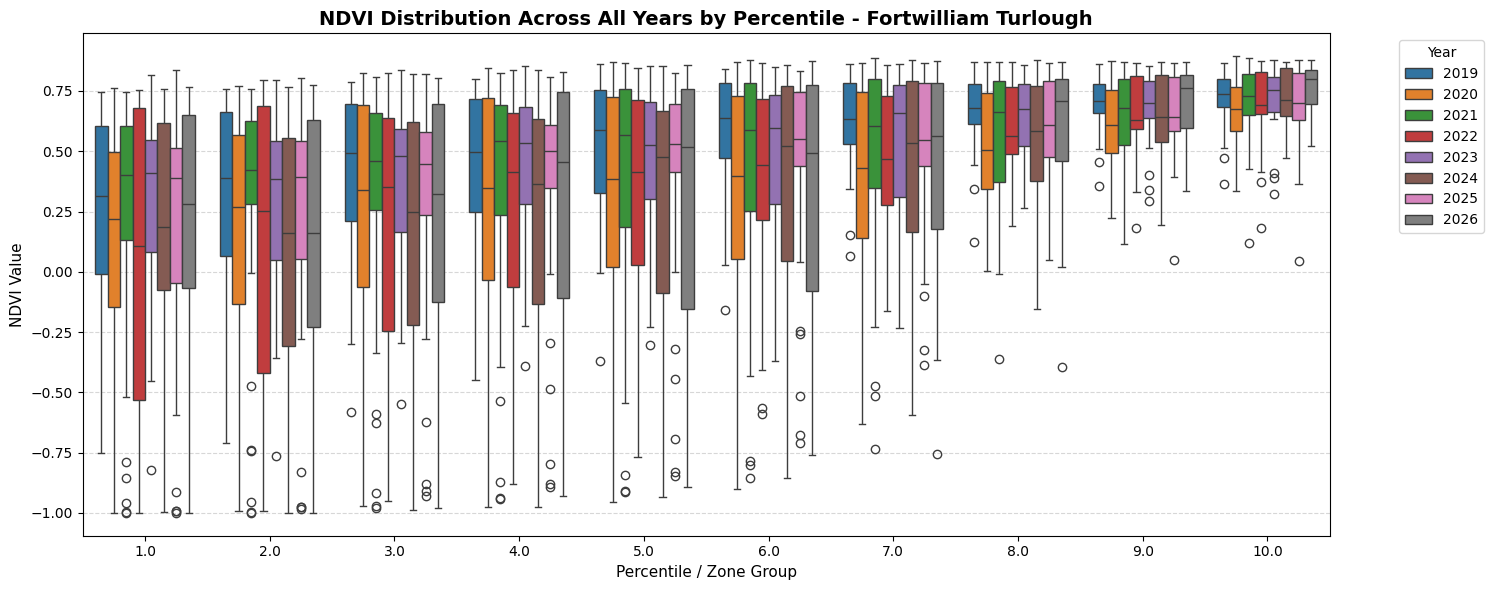

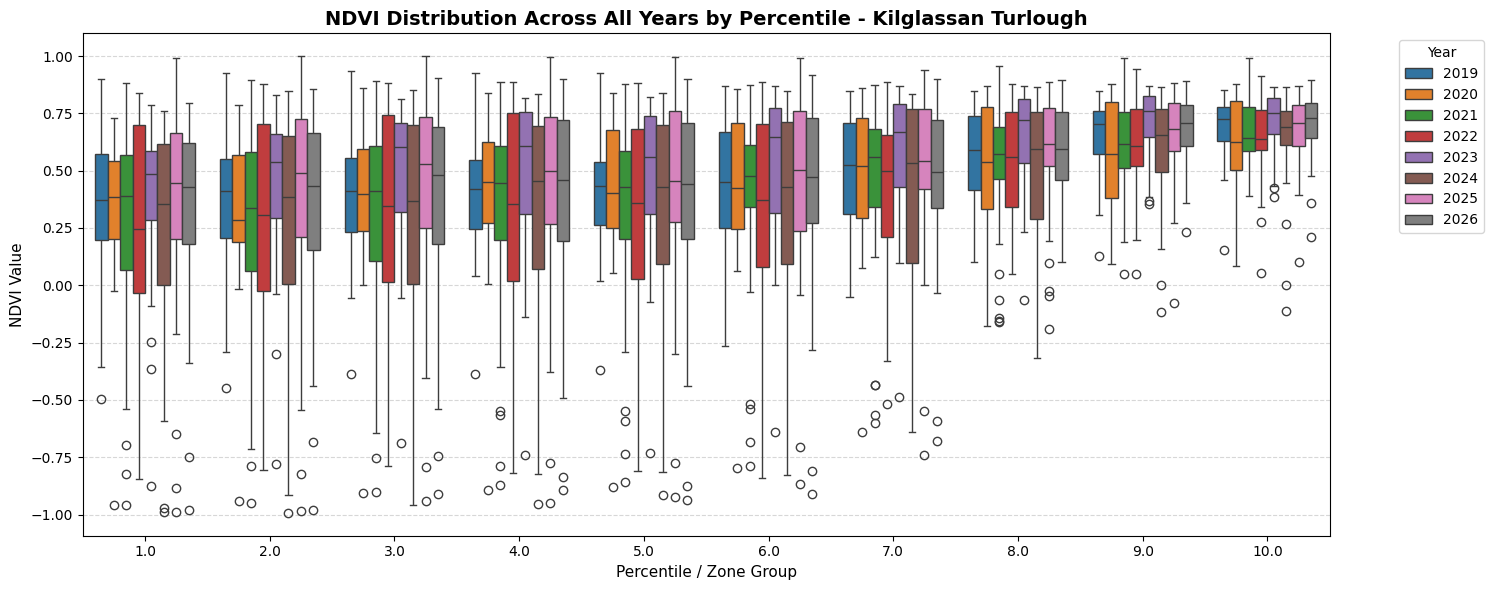

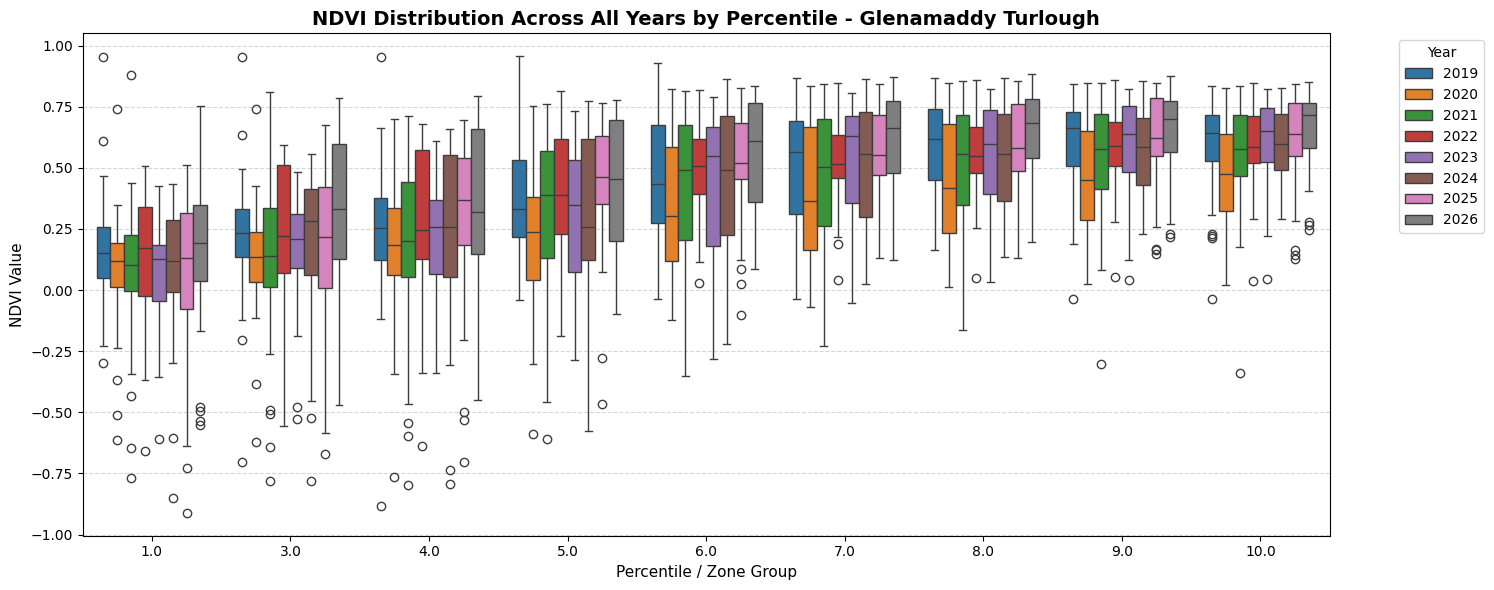

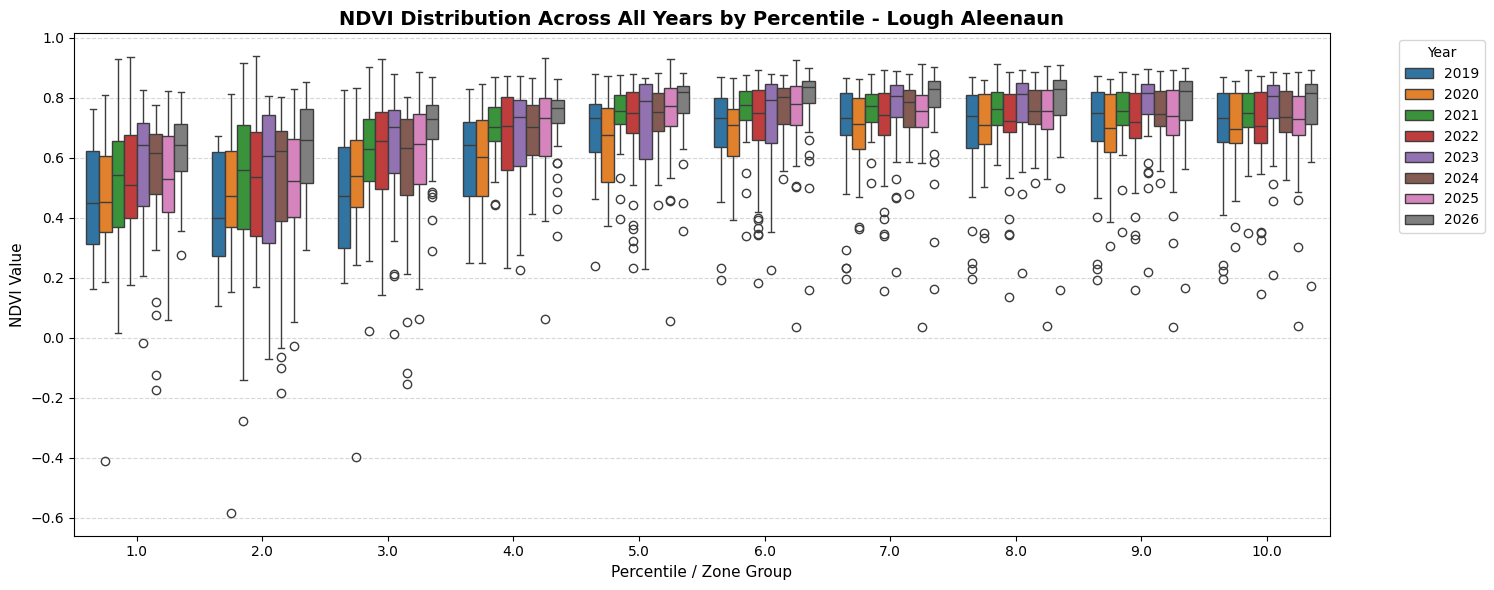

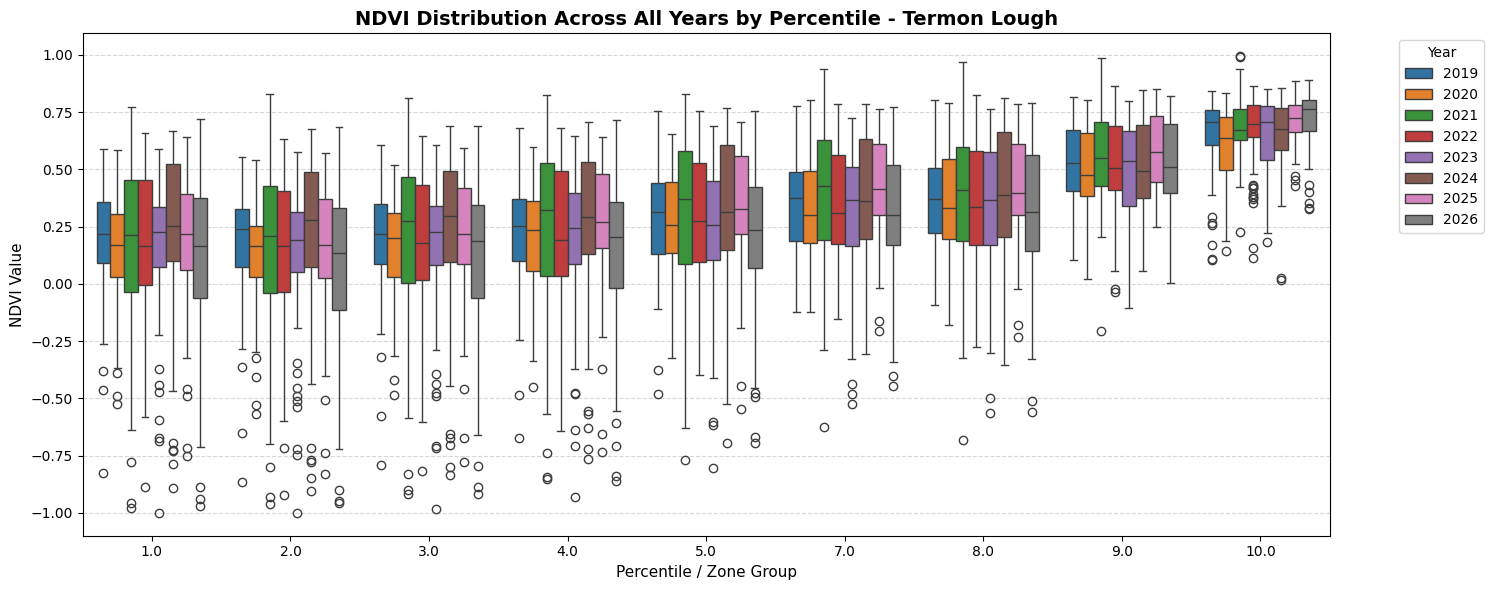

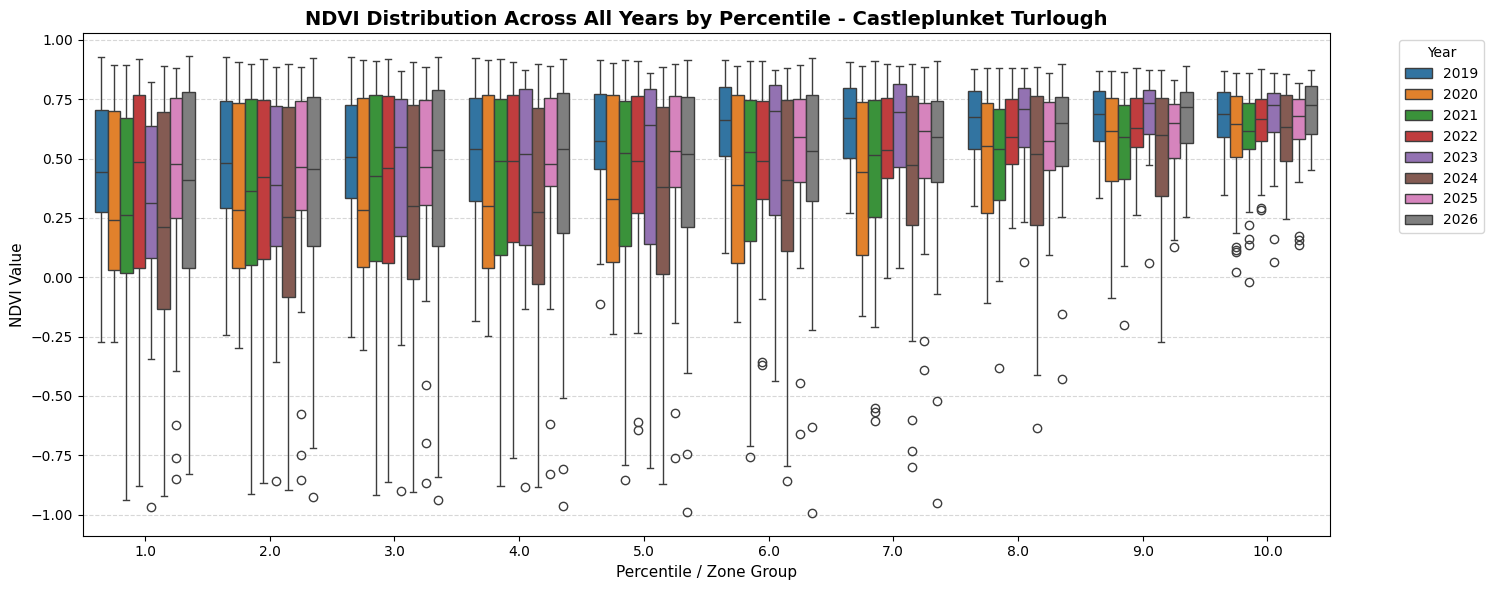

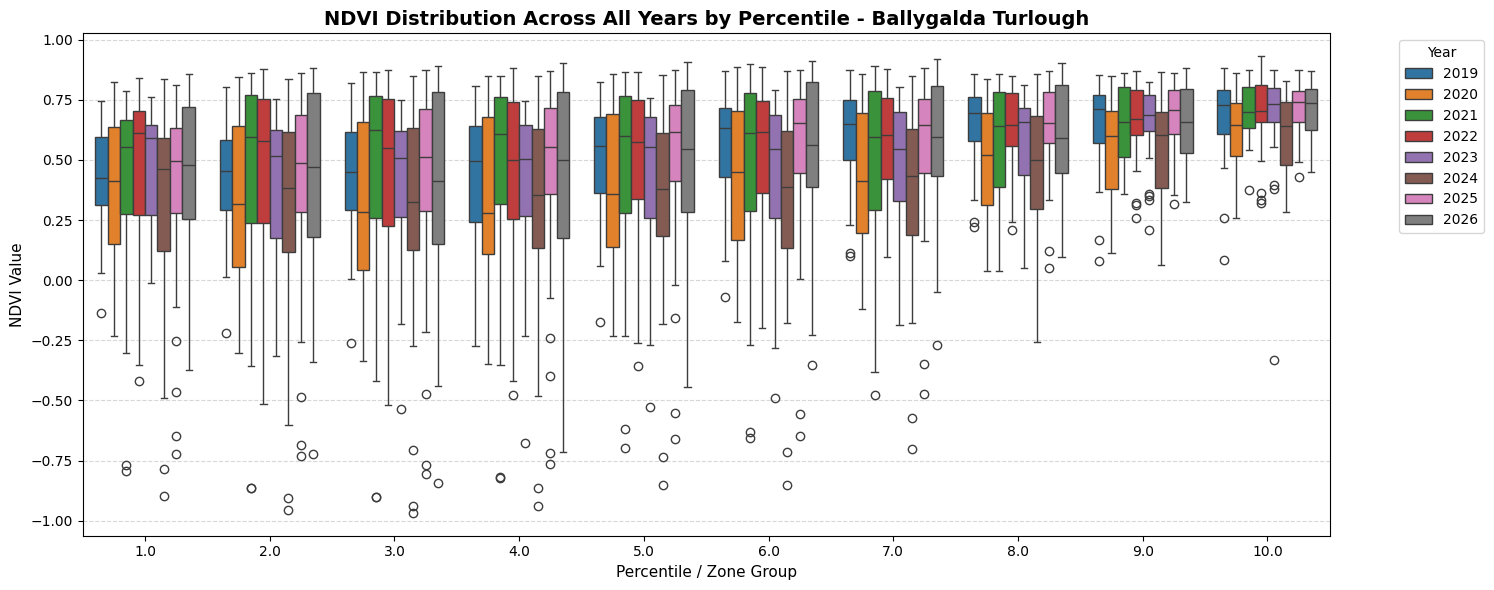

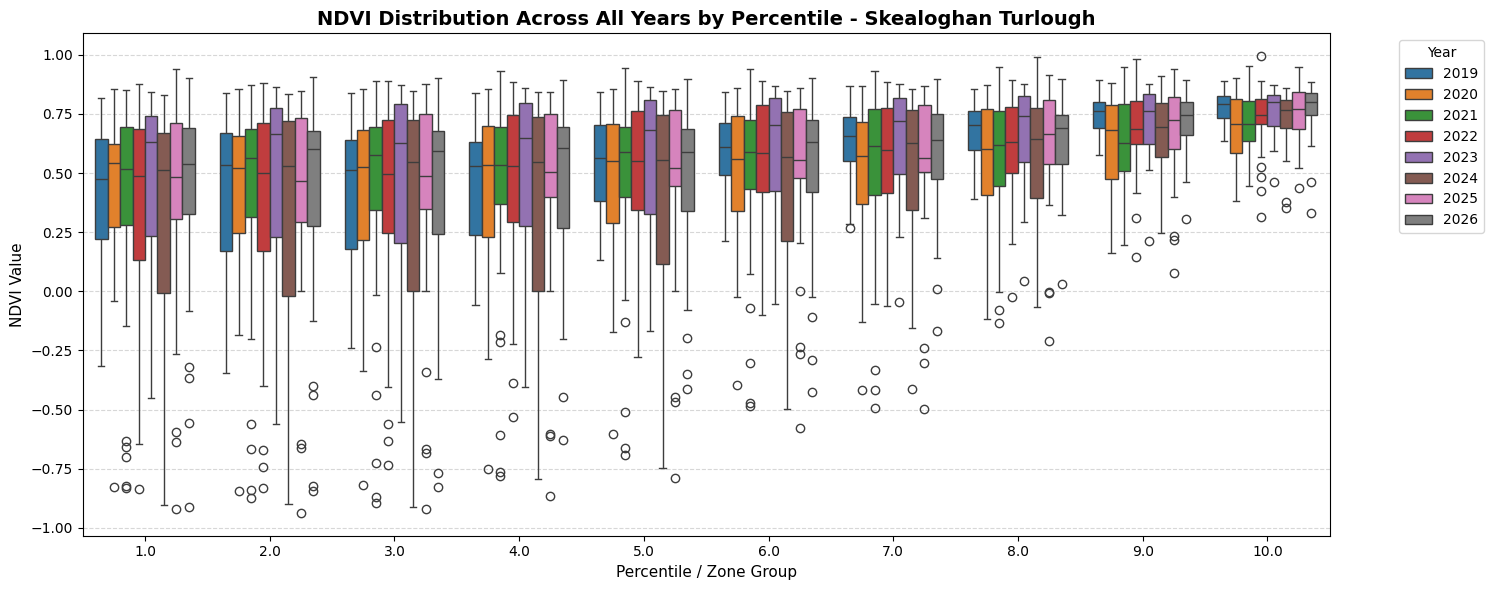

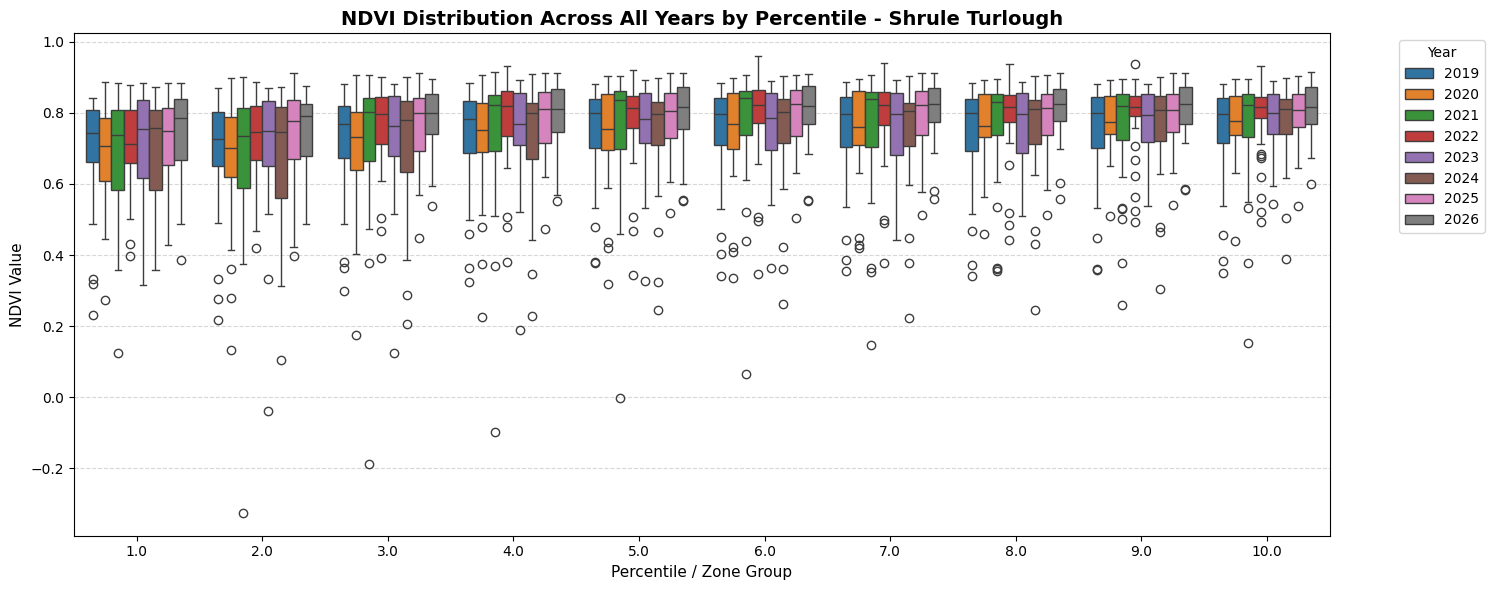

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# List of files to process
files = [
    '/content/Caherglassaun_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Fortwilliam_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Kilglassan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Glenamaddy_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Lough_Aleenaun_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Termon_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Castleplunket_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Ballygalda_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Skealoghan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Shrule_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv'
]

for file_path in files:
    if os.path.exists(file_path):
        # Get site name from the filename
        site_name = os.path.basename(file_path).split('_Zonal_')[0].replace('_', ' ')

        # Load CSV
        df = pd.read_csv(file_path)

        # Find columns
        ndvi_col = [col for col in df.columns if 'ndvi' in col.lower()]
        tile_col = [col for col in df.columns if 'tile' in col.lower() or 'zone_name' in col.lower()]
        year_col = [col for col in df.columns if 'year' in col.lower()]

        if not tile_col and 'zone_id' in df.columns:
            tile_col = ['zone_id']

        if ndvi_col and tile_col and year_col:
            col_name = ndvi_col[0]
            t_col = tile_col[0]
            y_col = year_col[0]

            # Clean, filter, and cast year to integer
            plot_df = df[[y_col, t_col, col_name]].dropna()
            plot_df[y_col] = plot_df[y_col].astype(int)

            # Create a single box plot showing percentiles grouped by year
            plt.figure(figsize=(15, 6))
            sns.boxplot(data=plot_df, x=t_col, y=col_name, hue=y_col, palette='tab10')
            plt.title(f'NDVI Distribution Across All Years by Percentile - {site_name}', fontsize=14, fontweight='bold')
            plt.xlabel('Percentile / Zone Group', fontsize=11)
            plt.ylabel('NDVI Value', fontsize=11)
            plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
            plt.grid(axis='y', linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()
        else:
            print(f"Warning: Required columns missing in {site_name}")

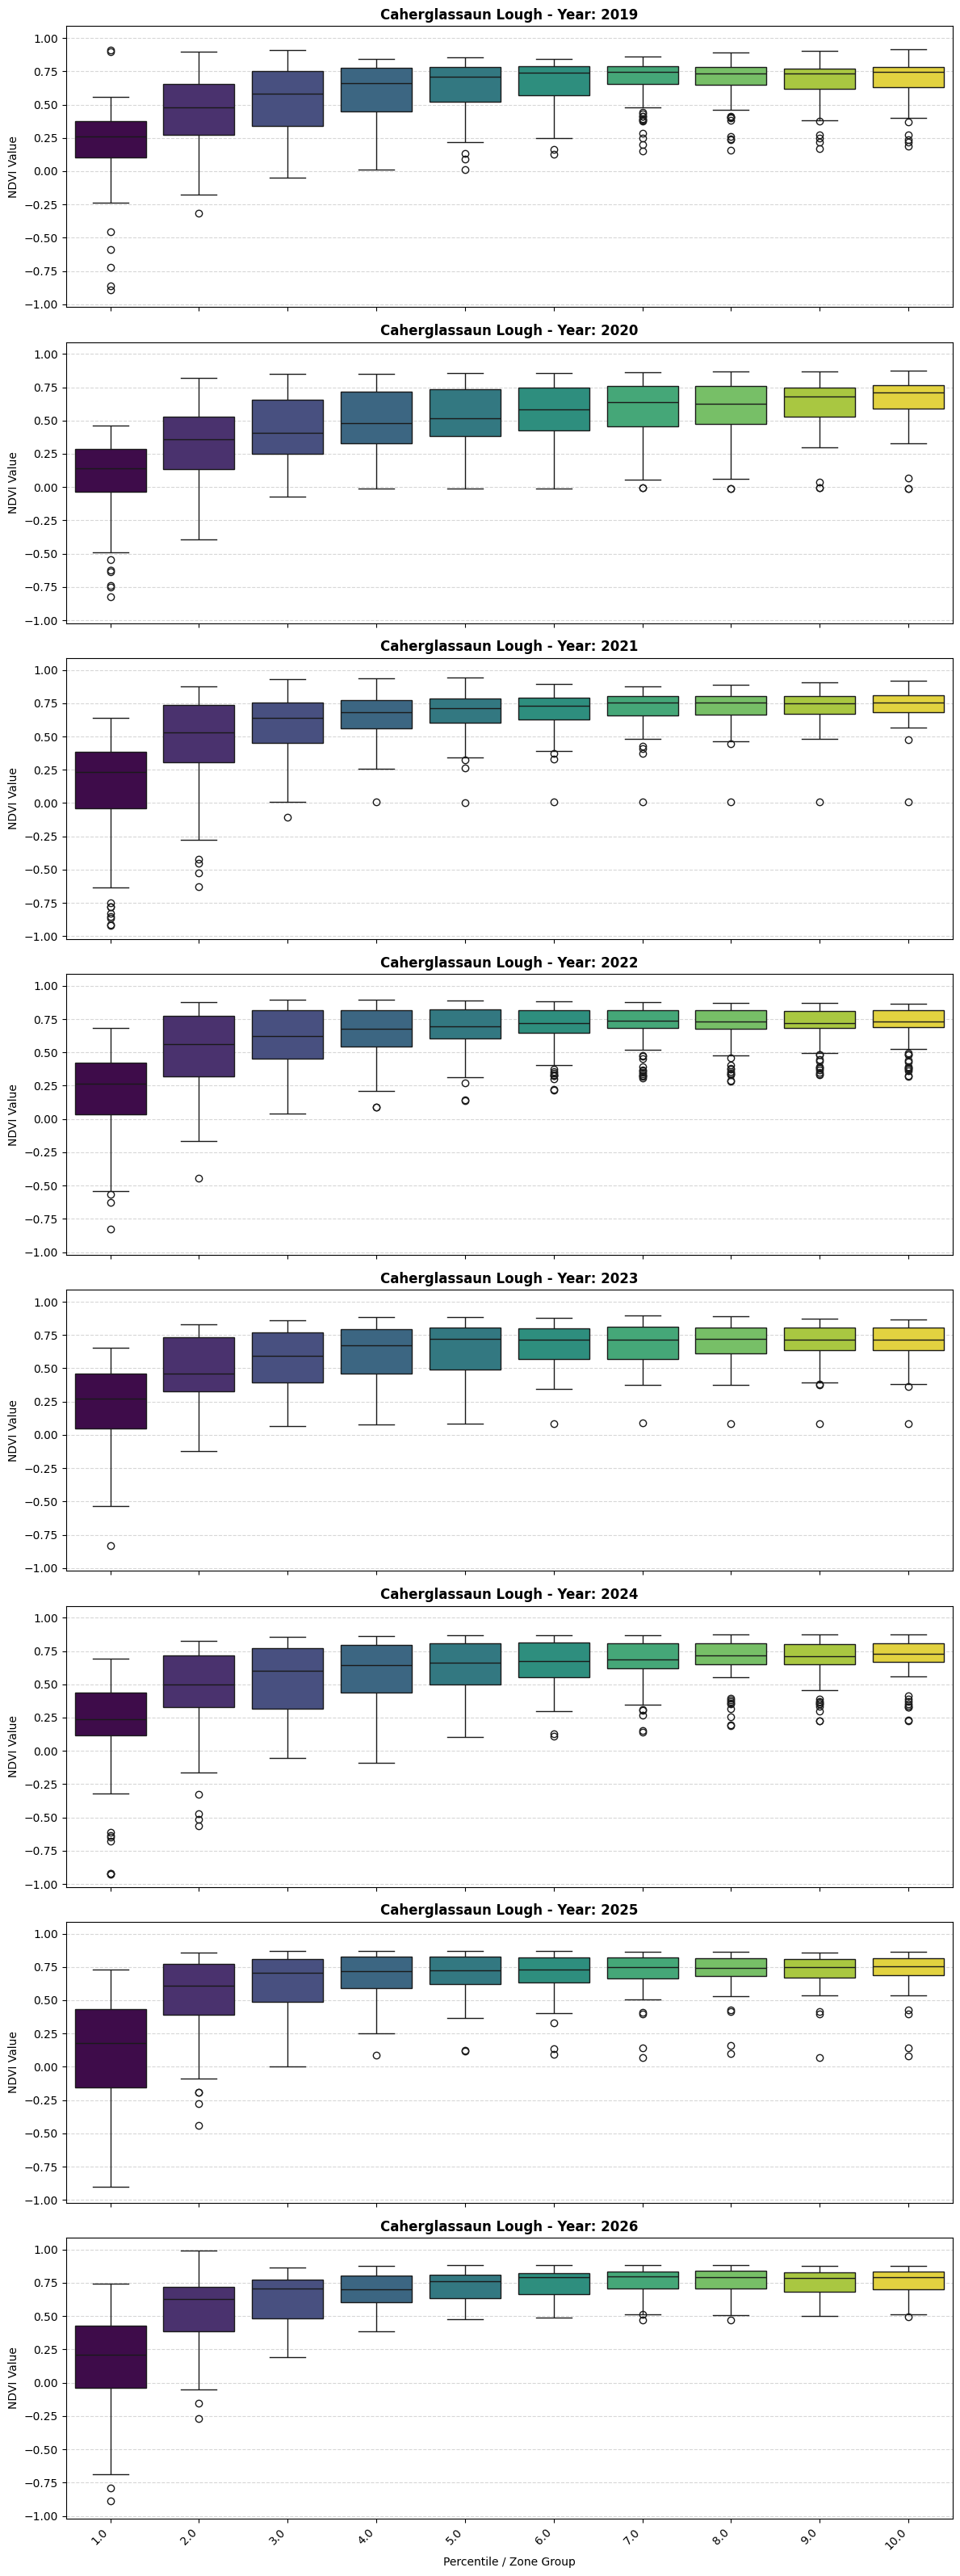

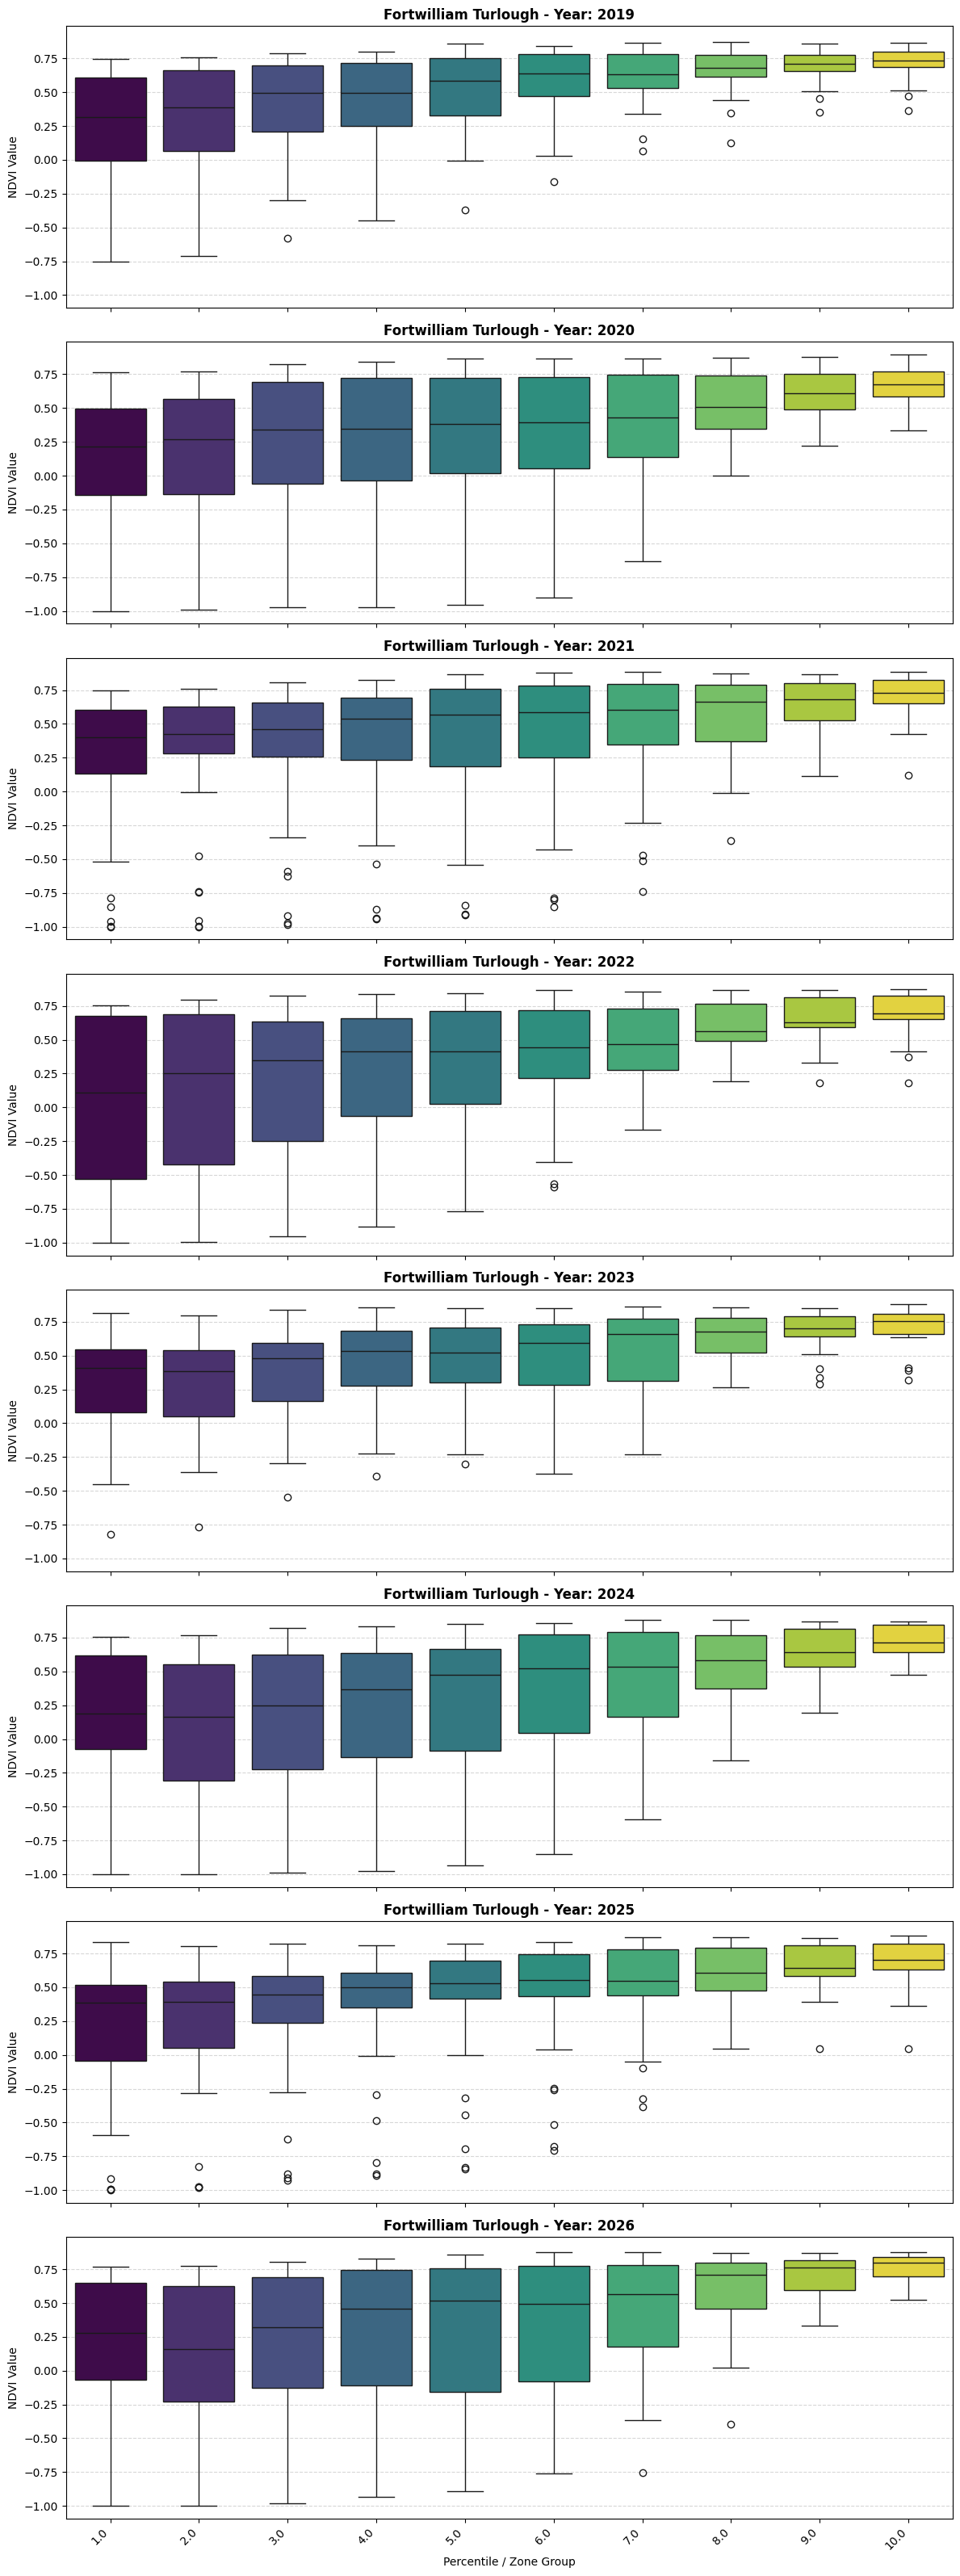

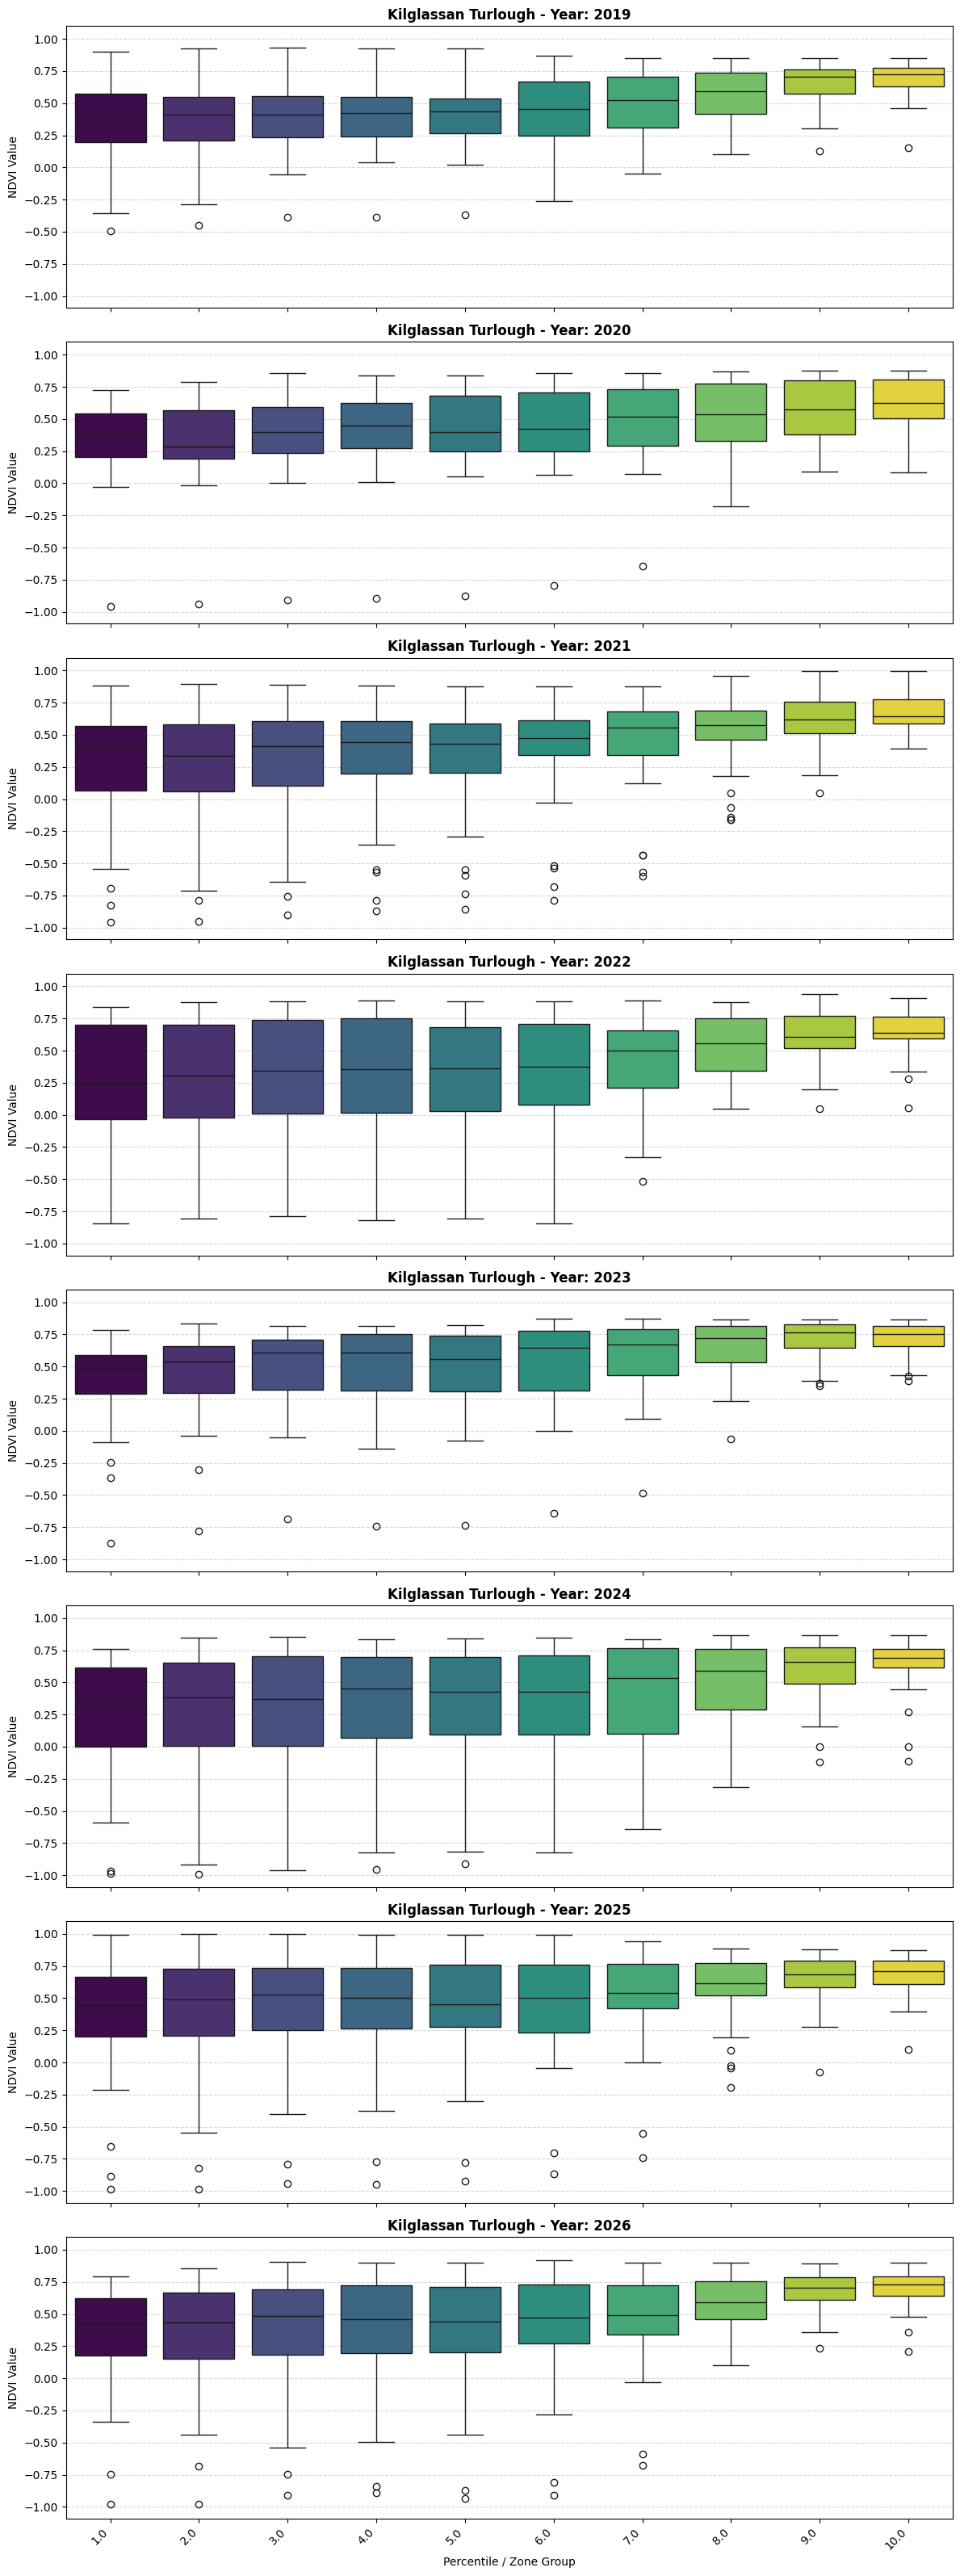

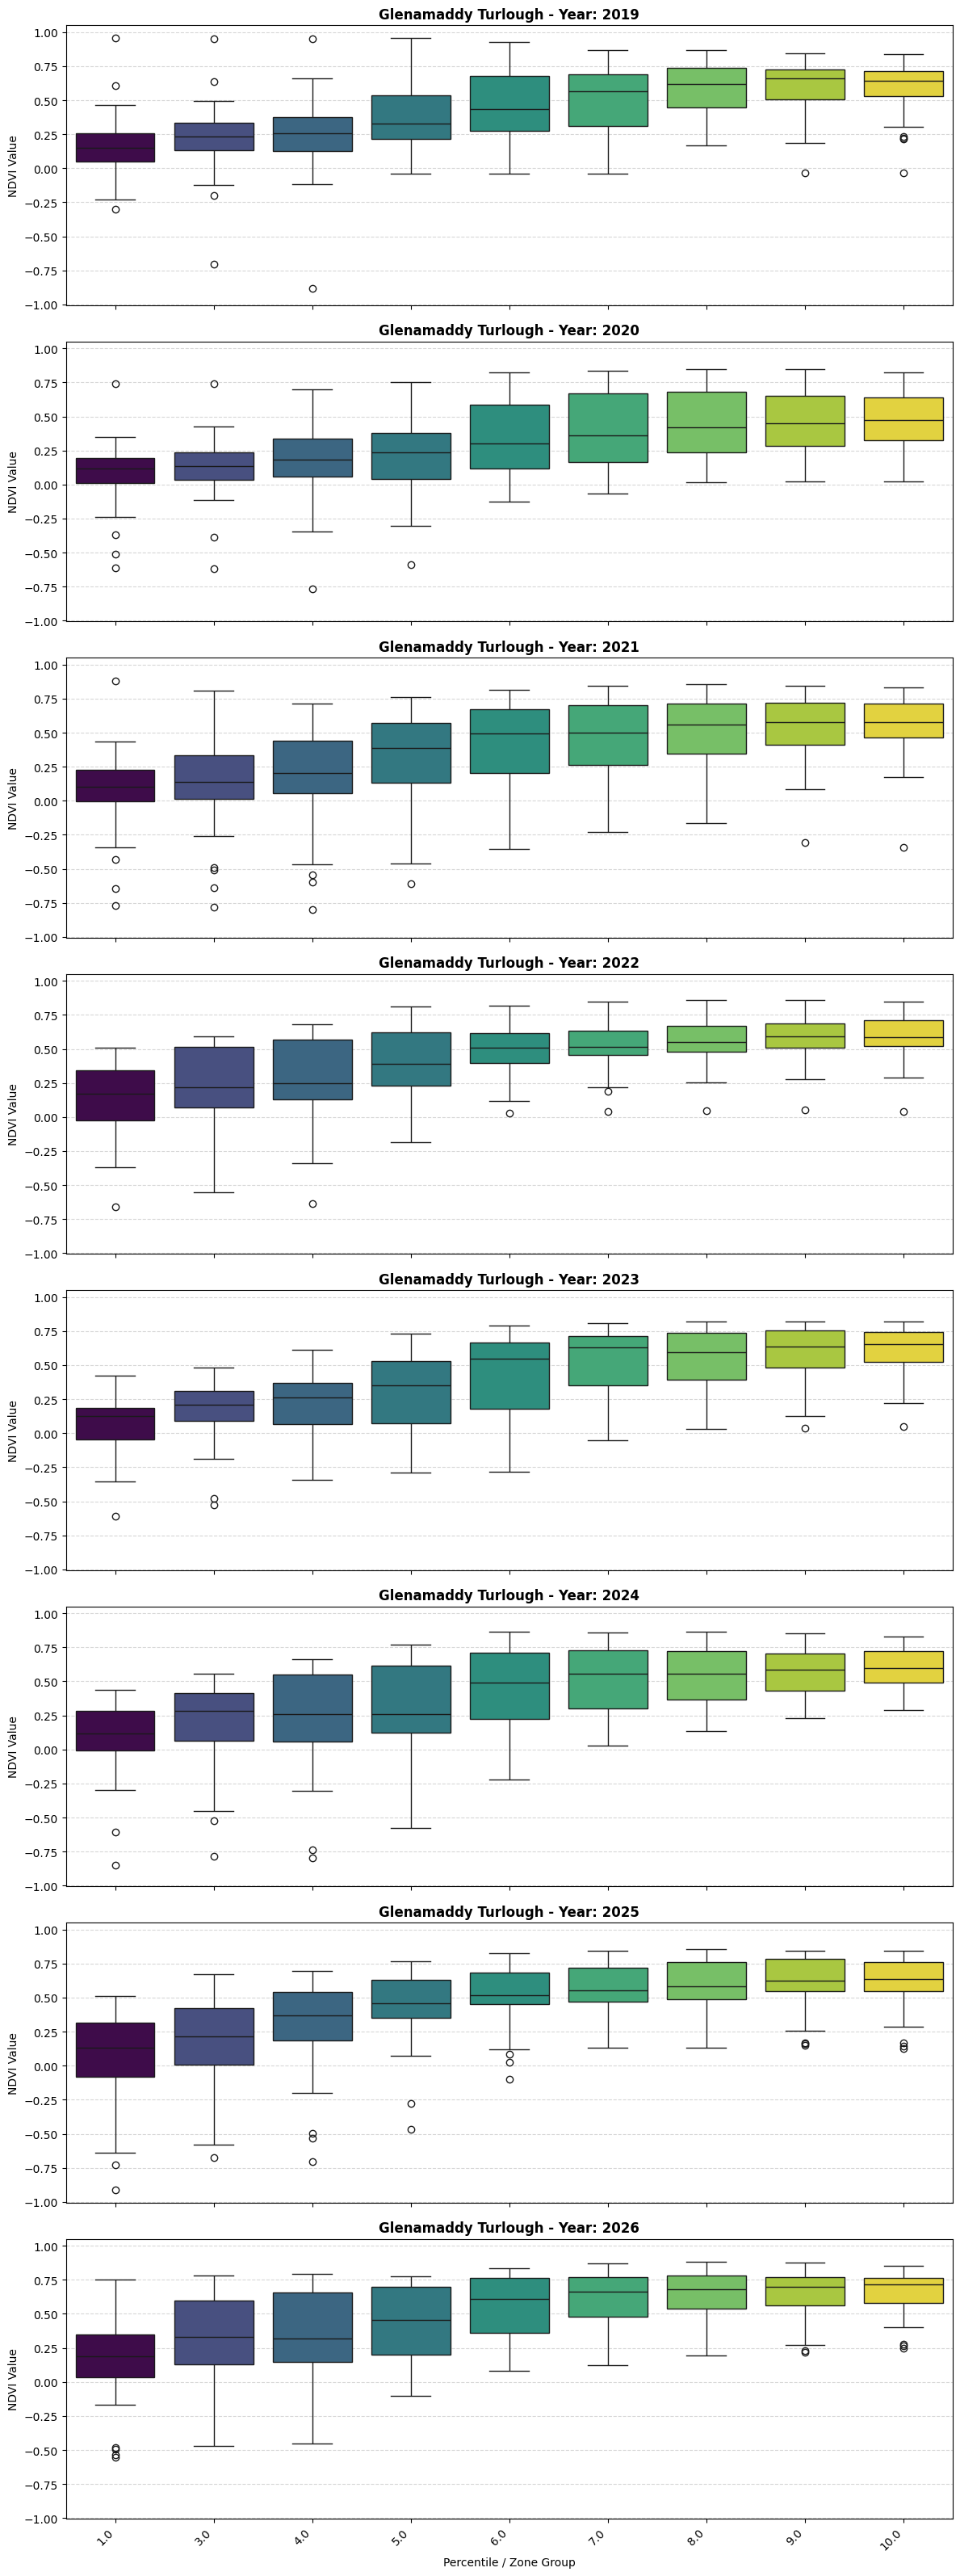

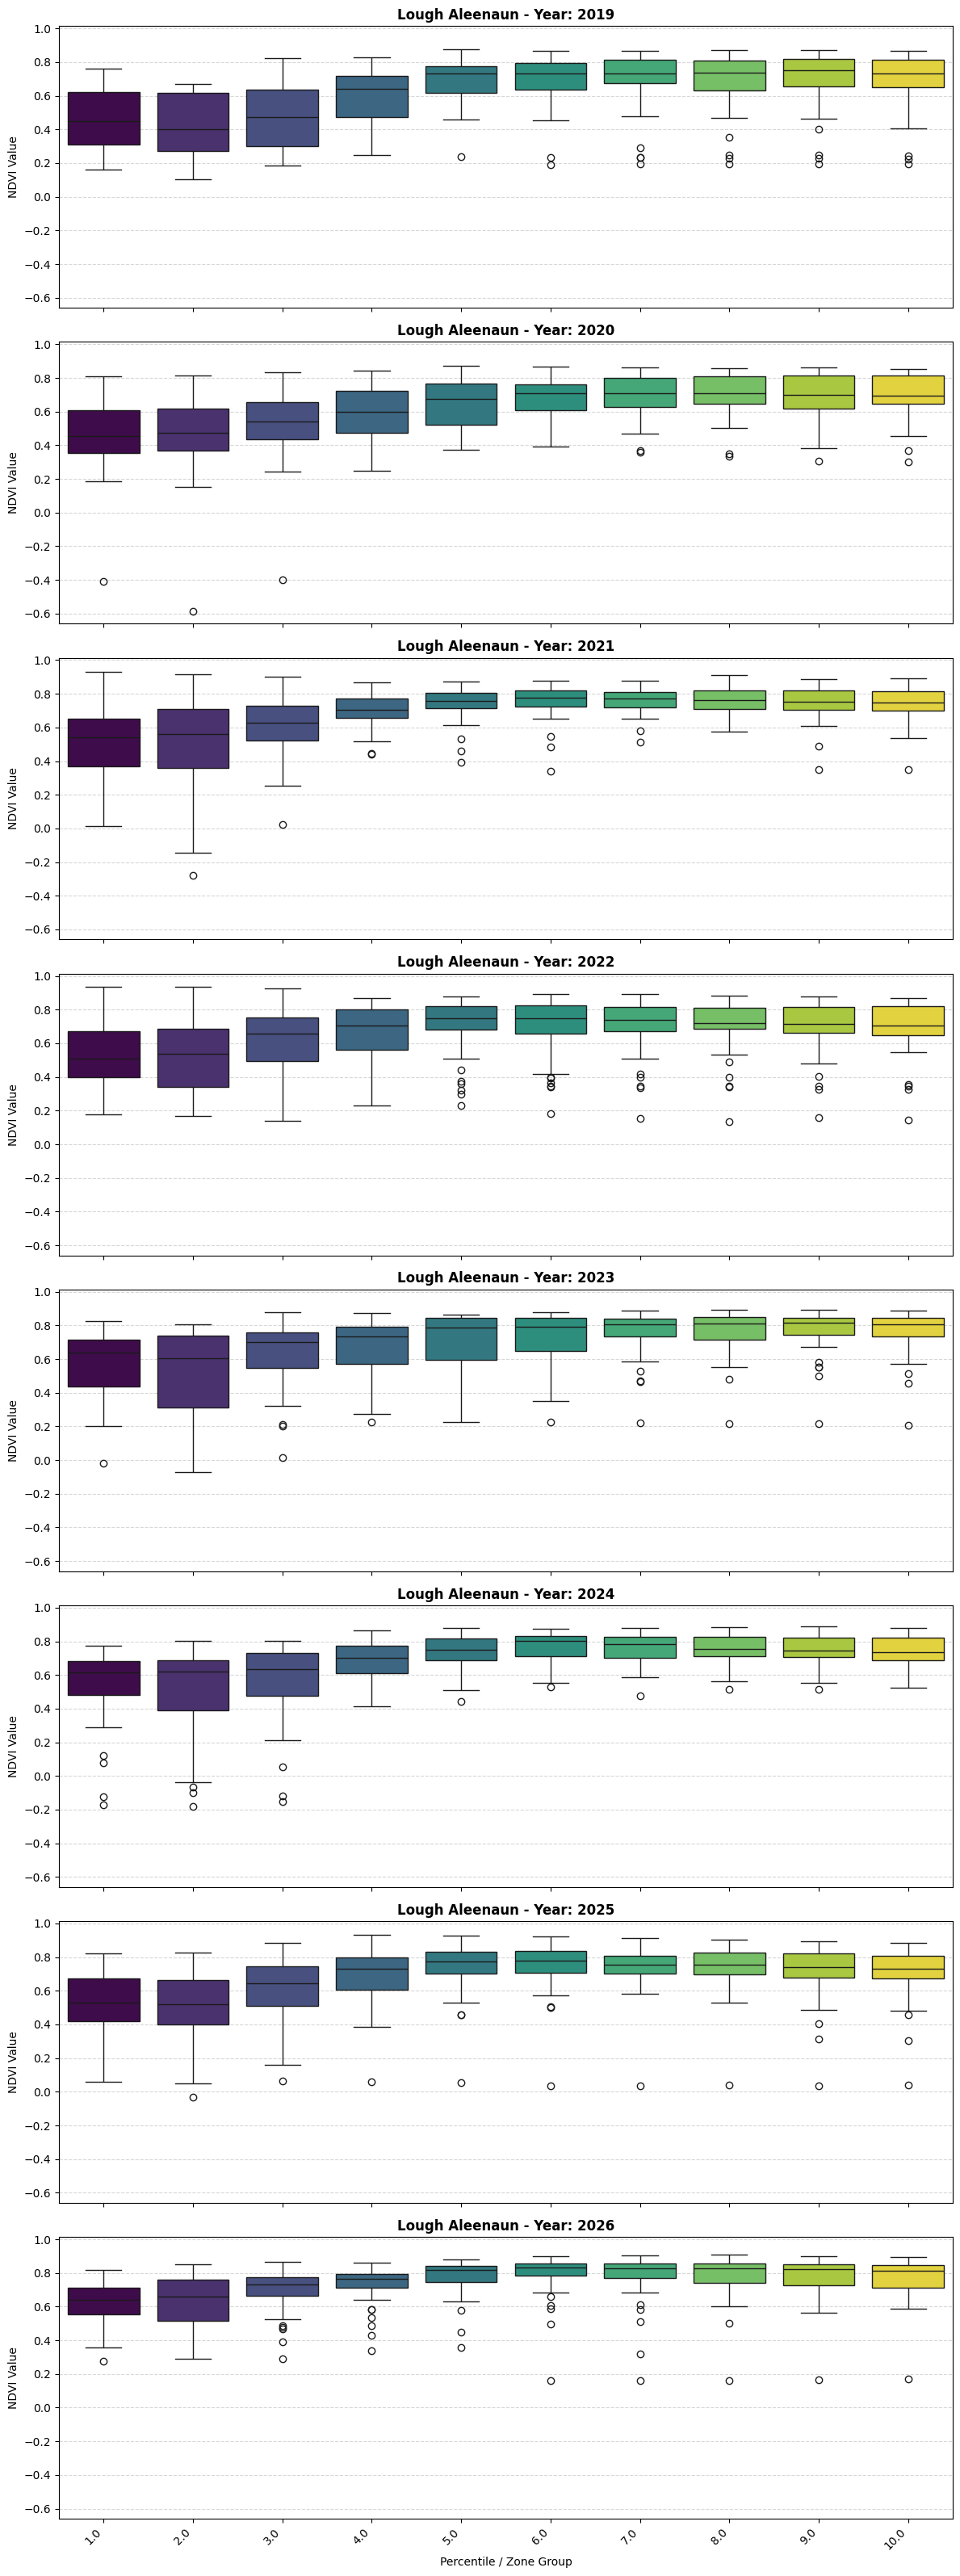

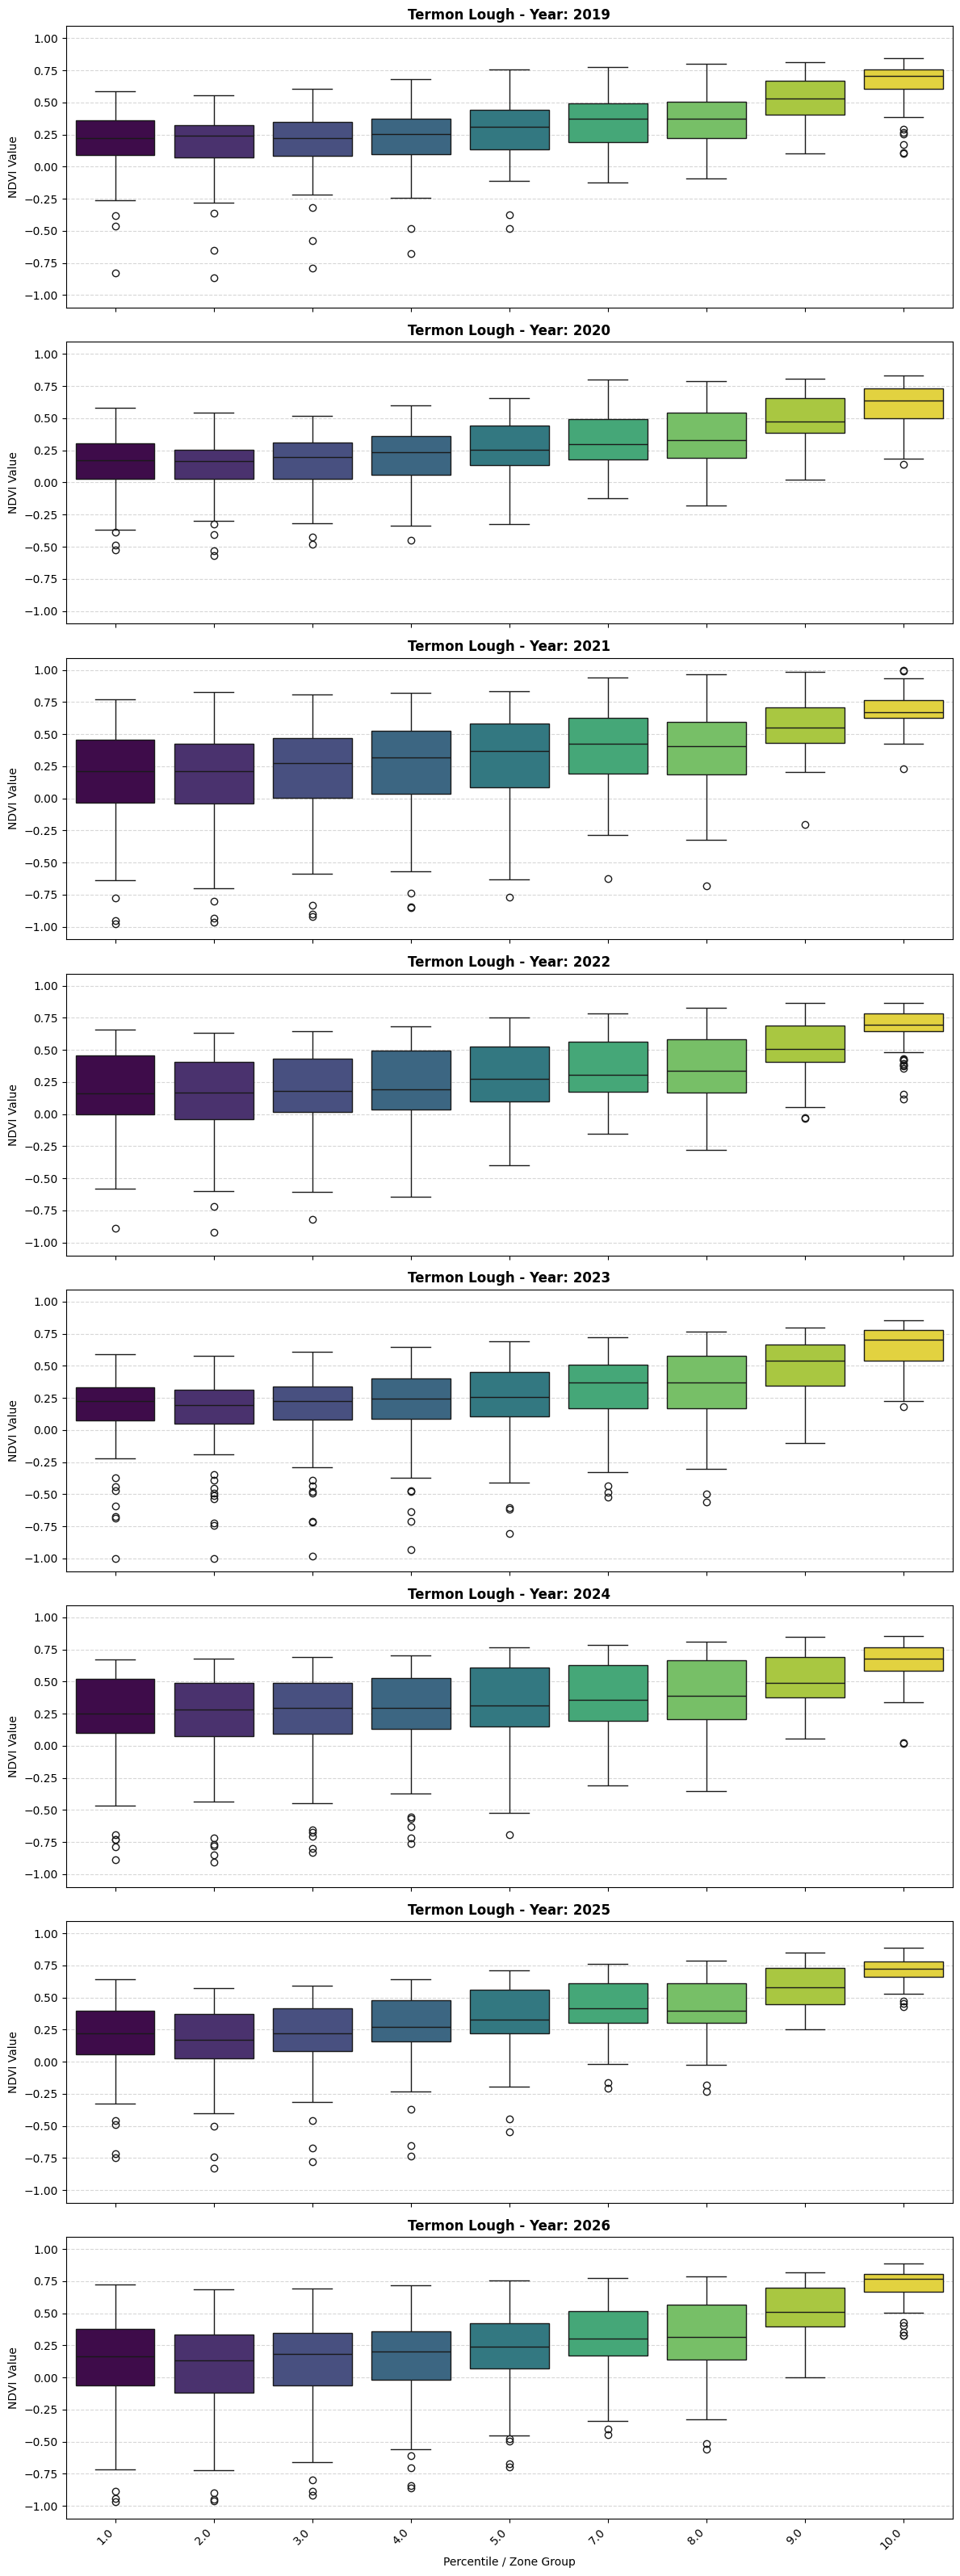

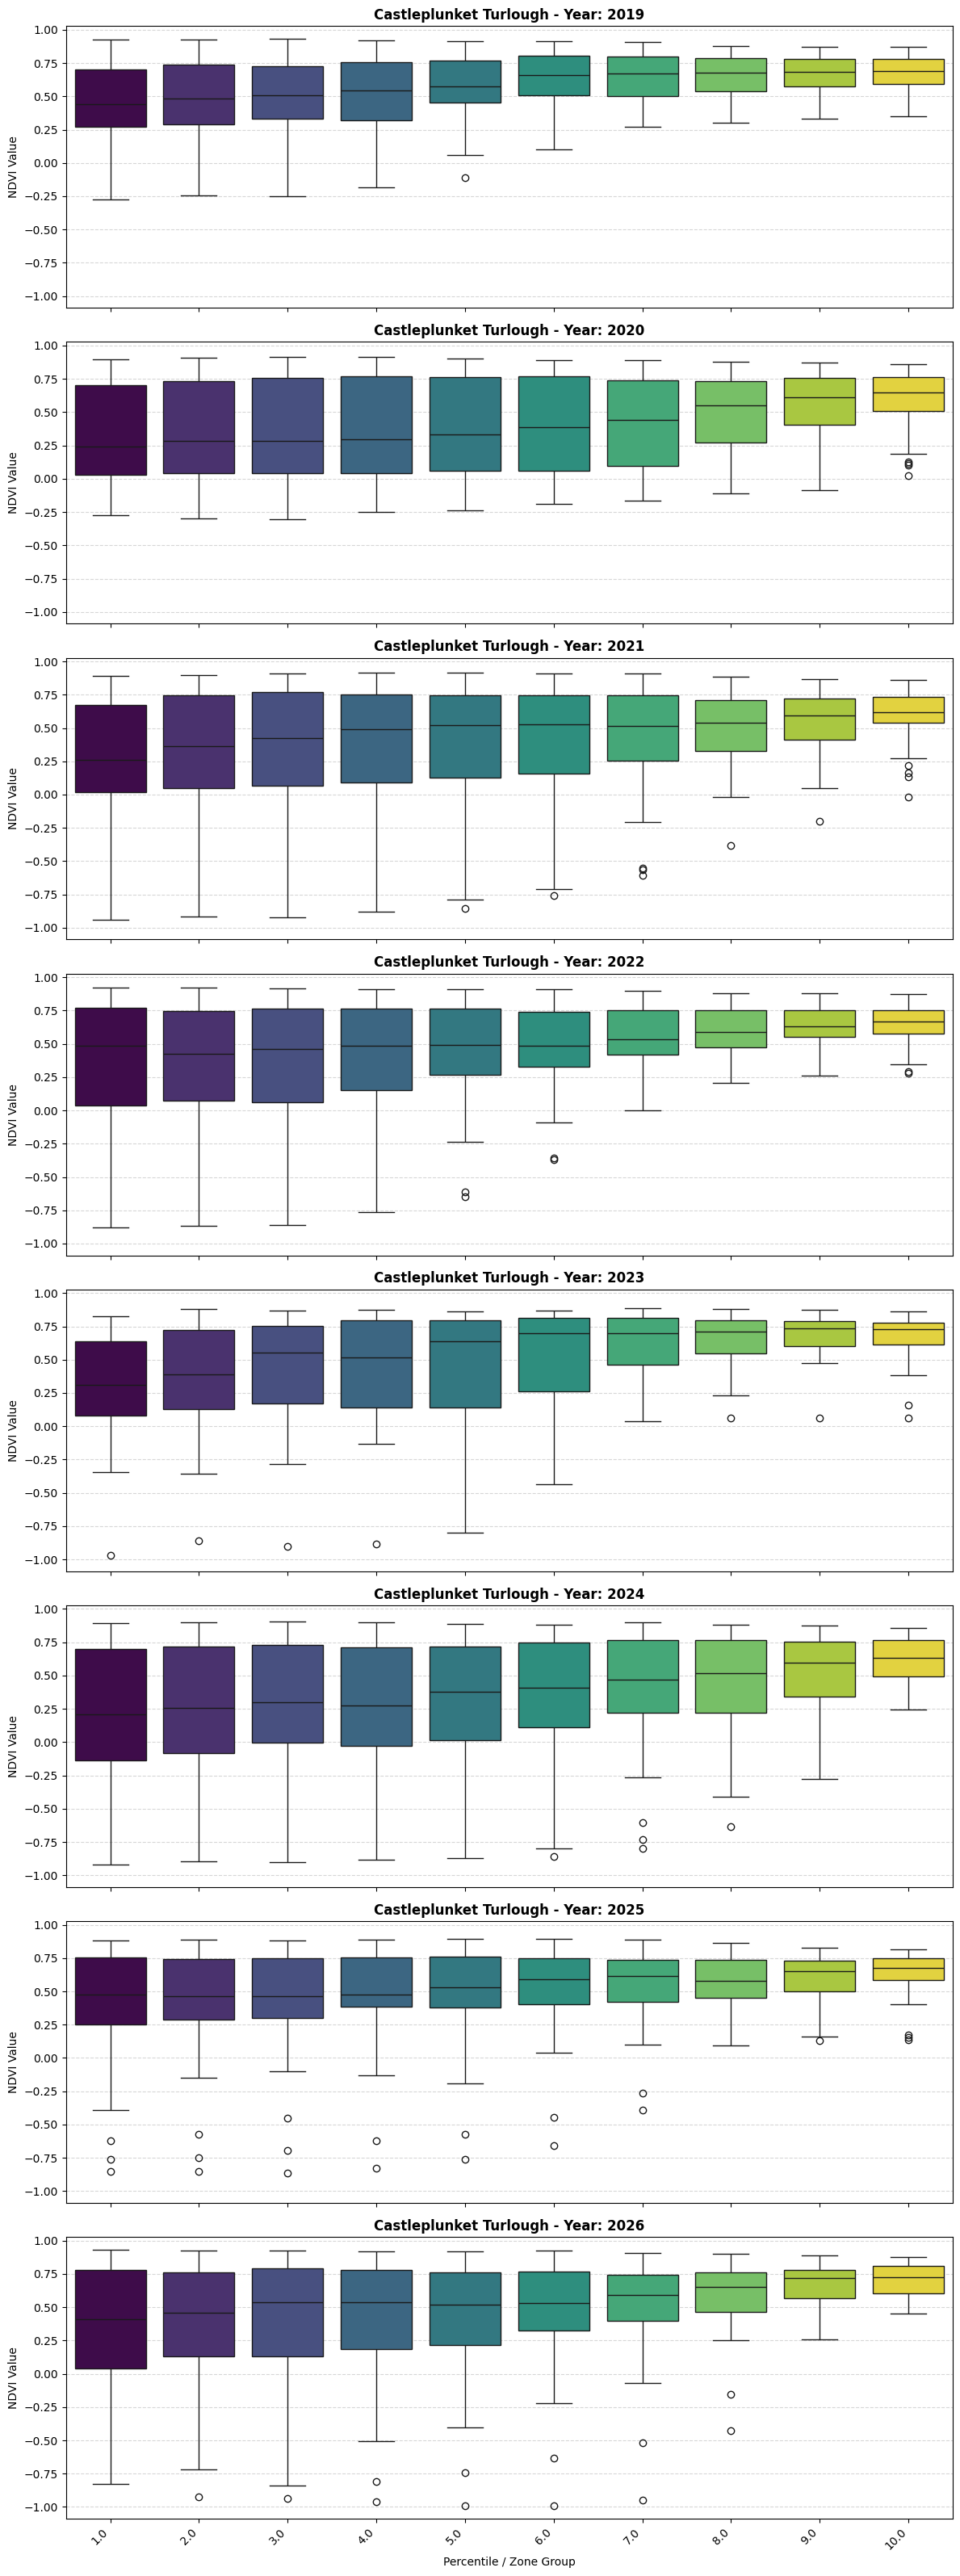

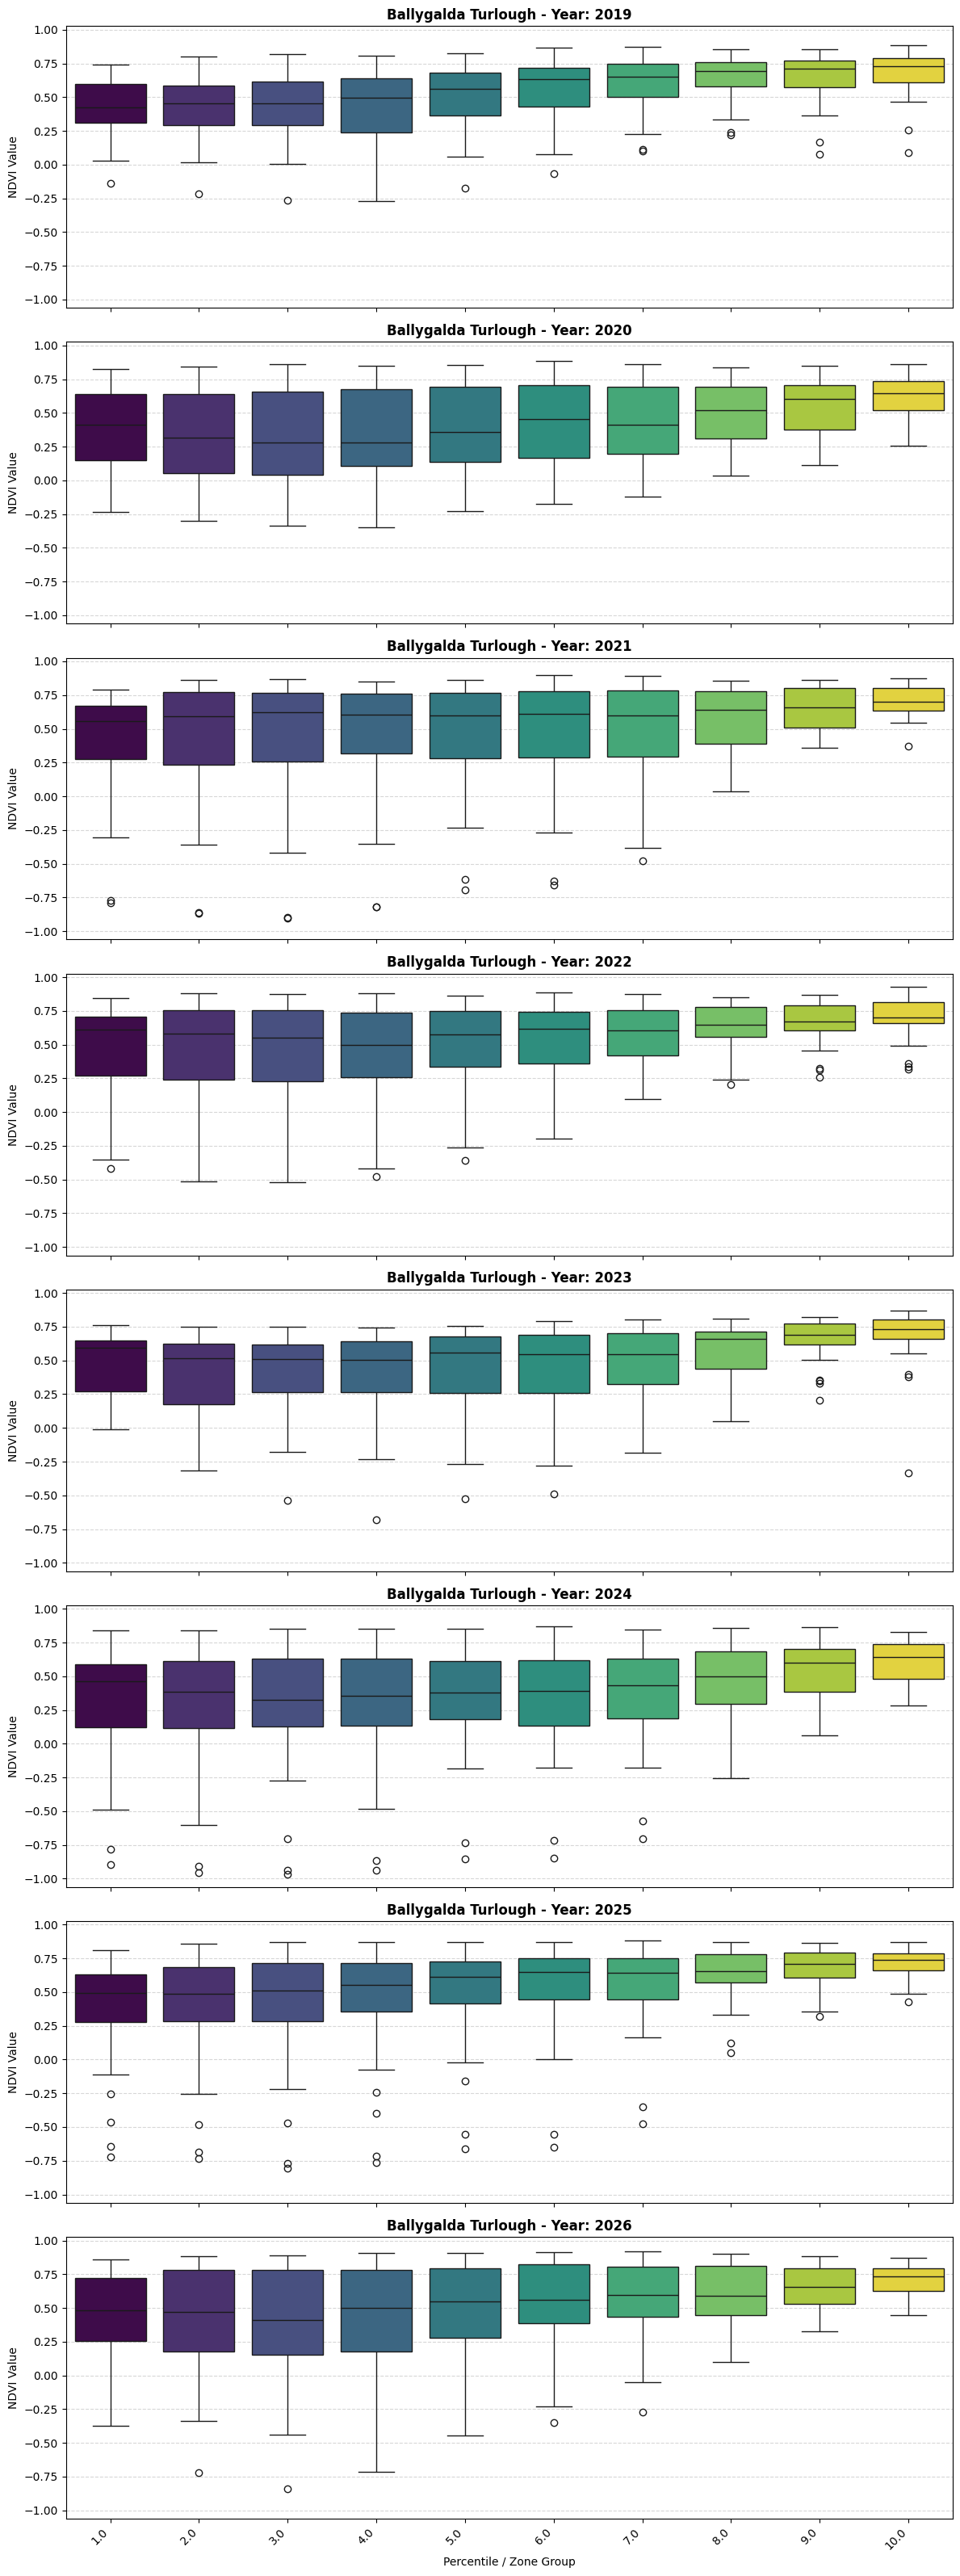

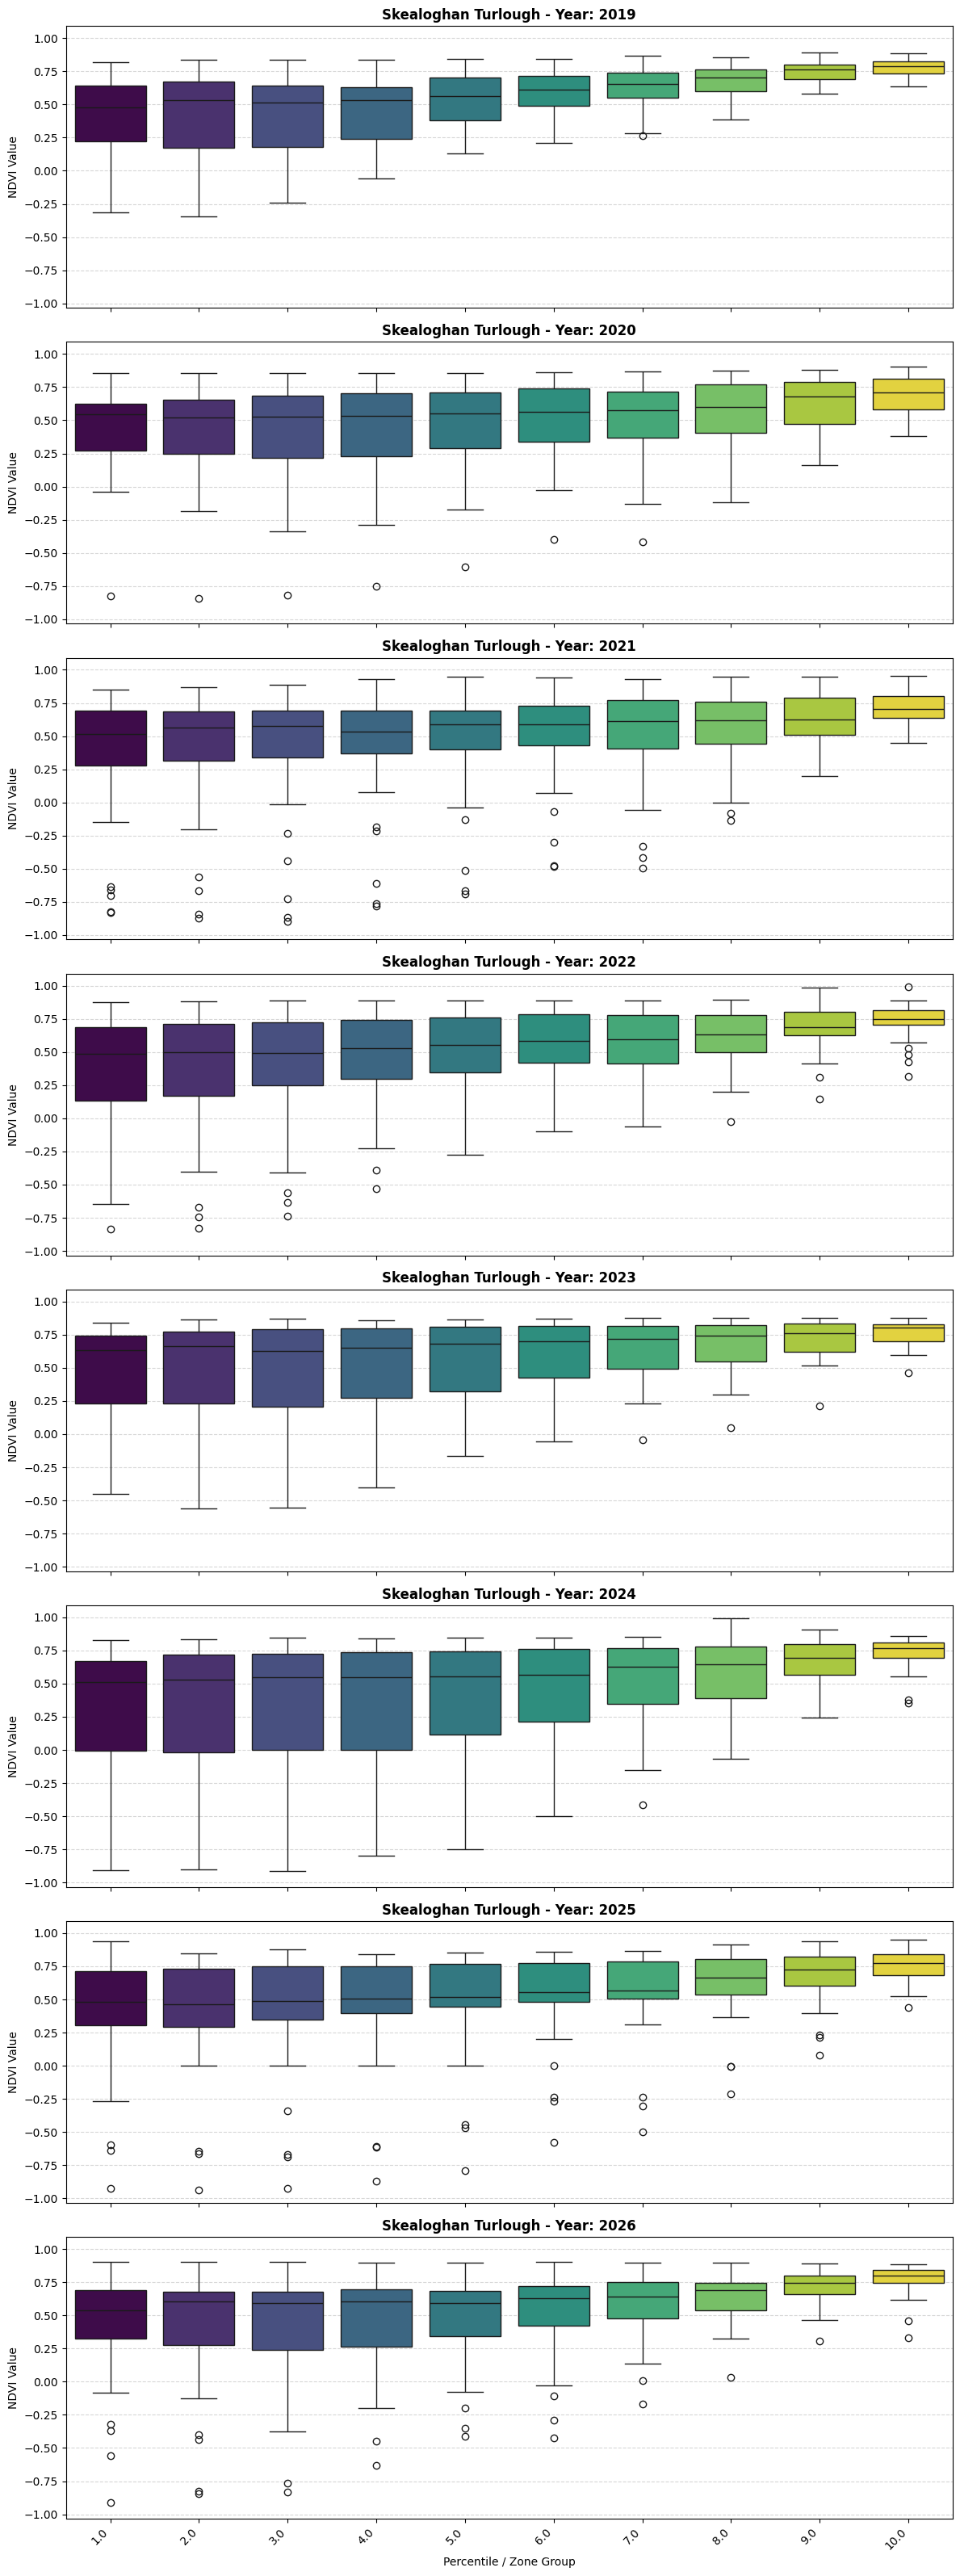

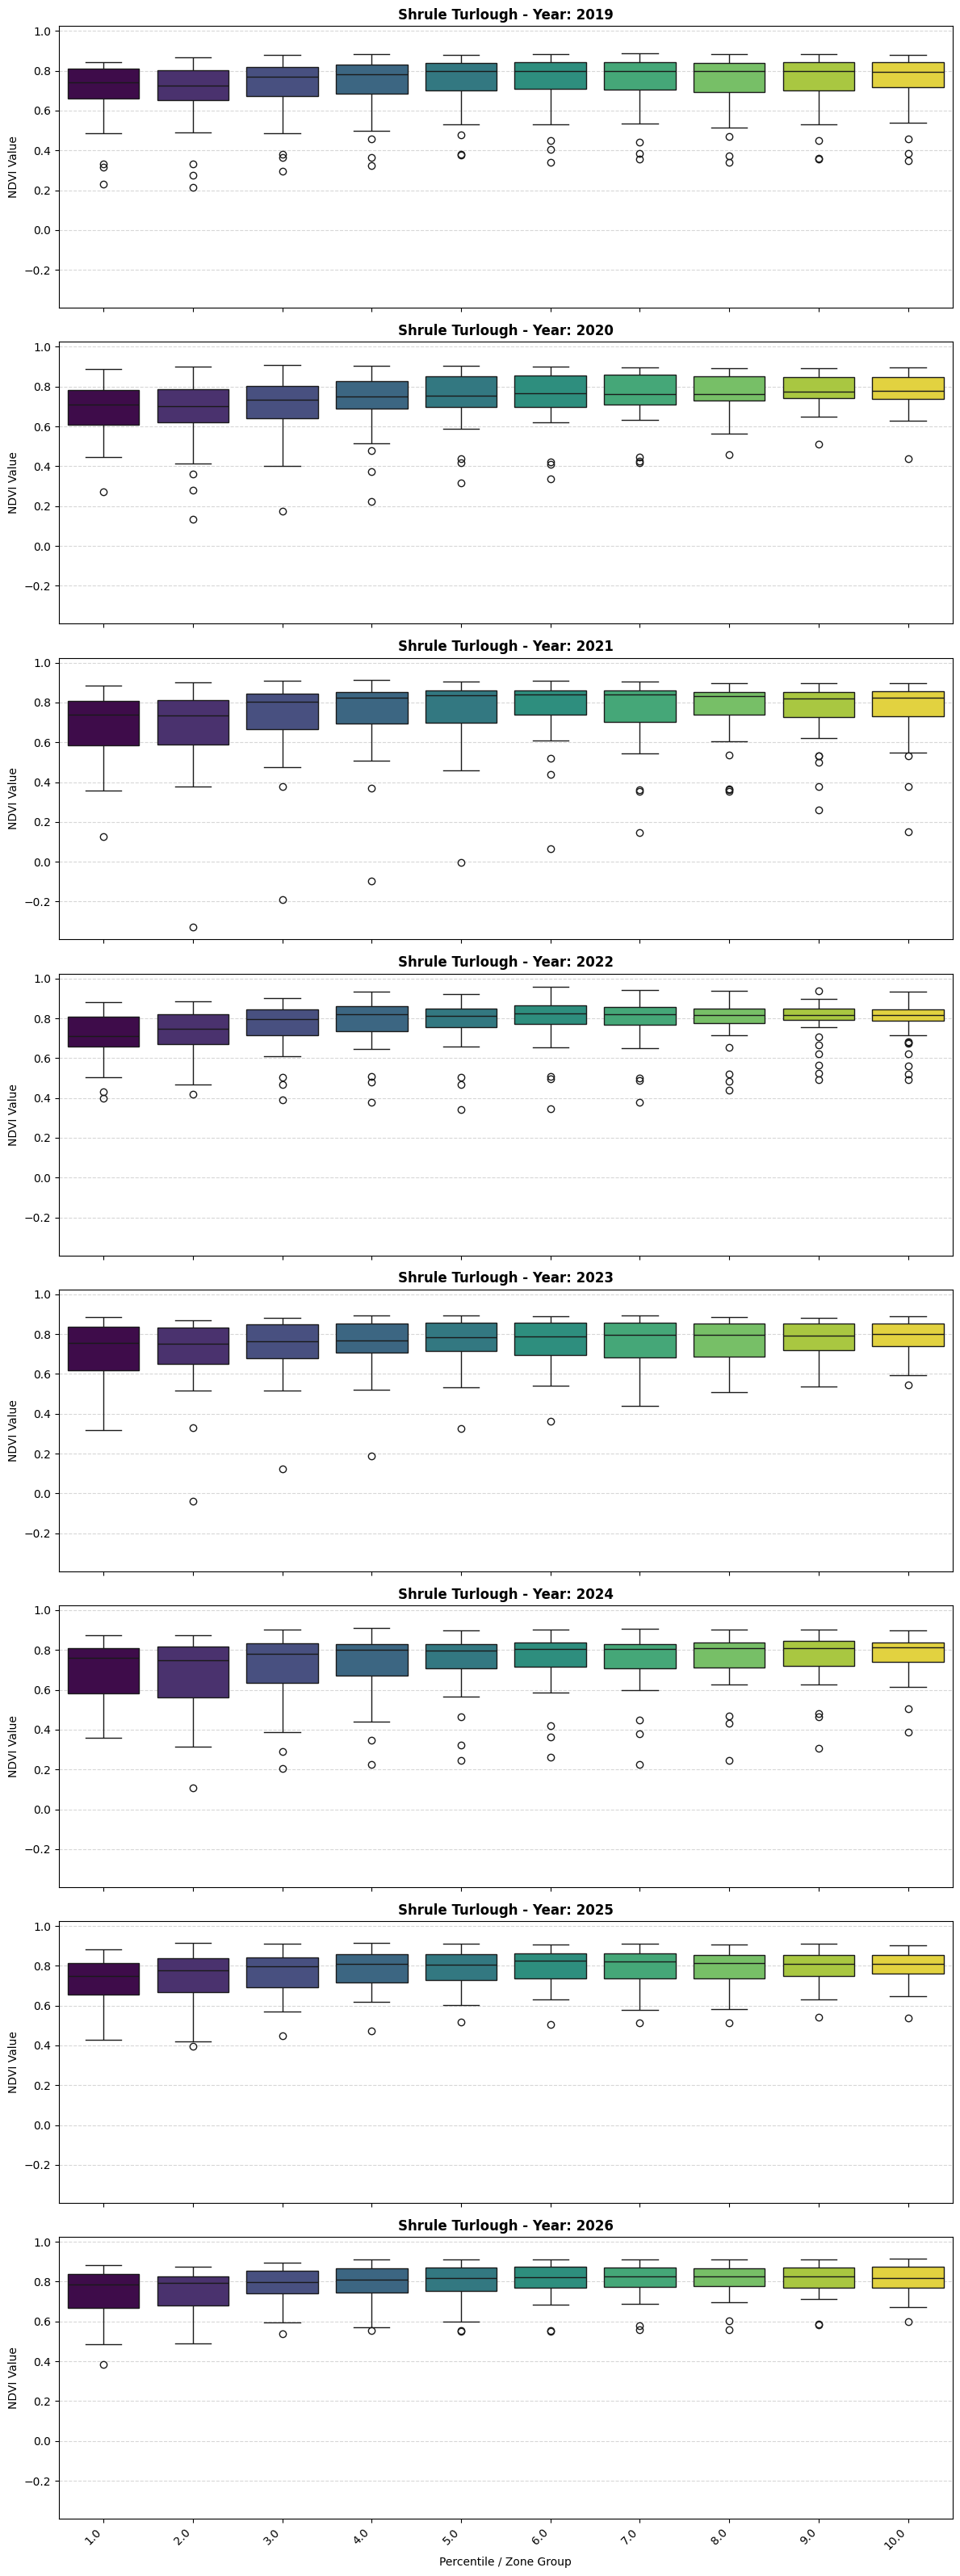

In [21]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# List of files to process
files = [
    '/content/Caherglassaun_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Fortwilliam_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Kilglassan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Glenamaddy_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Lough_Aleenaun_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Termon_Lough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Castleplunket_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Ballygalda_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Skealoghan_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv',
    '/content/Shrule_Turlough_Zonal_HY_2019-01-01_to_2026-10-31.csv'
]

for file_path in files:
    if os.path.exists(file_path):
        # Get site name from the filename
        site_name = os.path.basename(file_path).split('_Zonal_')[0].replace('_', ' ')

        # Load CSV
        df = pd.read_csv(file_path)

        # Find columns
        ndvi_col = [col for col in df.columns if 'ndvi' in col.lower()]
        tile_col = [col for col in df.columns if 'tile' in col.lower() or 'zone_name' in col.lower()]
        year_col = [col for col in df.columns if 'year' in col.lower()]

        if not tile_col and 'zone_id' in df.columns:
            tile_col = ['zone_id']

        if ndvi_col and tile_col and year_col:
            col_name = ndvi_col[0]
            t_col = tile_col[0]
            y_col = year_col[0]

            # Clean, filter, and cast year to integer
            plot_df = df[[y_col, t_col, col_name]].dropna()
            plot_df[y_col] = plot_df[y_col].astype(int)

            # Get unique years sorted
            unique_years = sorted(plot_df[y_col].unique())

            # Create separate figure with subplots for each year for the current site
            fig, axes = plt.subplots(len(unique_years), 1, figsize=(12, 4 * len(unique_years)), sharex=True, sharey=True)
            if len(unique_years) == 1:
                axes = [axes]

            for ax, year in zip(axes, unique_years):
                year_df = plot_df[plot_df[y_col] == year]
                sns.boxplot(data=year_df, x=t_col, y=col_name, hue=t_col, palette='viridis', ax=ax, legend=False)
                ax.set_title(f'{site_name} - Year: {year}', fontsize=12, fontweight='bold')
                ax.set_xlabel('Percentile / Zone Group' if ax == axes[-1] else '', fontsize=10)
                ax.set_ylabel('NDVI Value', fontsize=10)
                ax.grid(axis='y', linestyle='--', alpha=0.5)

            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()
        else:
            print(f"Warning: Required columns (NDVI, Tile, or Year) missing in {site_name}")